## Mô hình toán đầy đủ: $S_a(t)$ và bão hoà tĩnh mạch $S_v(t)$ khi lặn

Notebook chạy toàn bộ mô hình trong ghi chú "Mô hình Toán" (E0, E1, $S_a(t)$ với $\Delta S_a(T_d)$, E2) trên dữ liệu đã merge (`penguin_merged.csv`, `penguin_dives.csv` từ `merge_data_new_v2`).

**Công thức:**

- **E0:** $S=\dfrac{P^{n}}{P_{50}^{n}+P^{n}}$, $P_{50}=28{,}2$ mmHg, $n=2{,}93$.
- **E1:** $t_{start}=t-t_{in\_dive}$; $t_{min}=(t-t_{start})/60$; $x=t_{min}/T_d$; $t_{end}=t_{start}+60T_d$; $z_{max}=\max(\text{depth})$.
- **$S_a(t)$:** $0{,}97$ nếu $t_{min}<0$; $0{,}987-\Delta S_a x^{5}$ nếu $0\le t_{min}\le T_d$; $0{,}97-(0{,}97-S_{end})e^{-(t_{min}-T_d)/\tau_a}$ nếu $t_{min}>T_d$; với $\Delta S_a=\mathrm{clip}(-0{,}141+0{,}183\ln T_d;\,0;\,0{,}6)$ và $S_{end}=0{,}987-\Delta S_a$.
- **E2:** $\dfrac{dS_v}{dt}=\dfrac{[S_a(t)-g(t)]-S_v}{r}$, với $g=m\,r$, $r=V_v/Q$. Rời rạc hoá bước $\Delta t=0{,}05$ phút: $S_{j+1}=S_je^{-\Delta t/r}+(1-e^{-\Delta t/r})\,[S_a(t_j)-g(t_j)]$.
- **$g(t)$ theo 6 giai đoạn:** $g_{rest}$ (trước lặn và sau lặn quá 3 phút), $g_1,g_2,g_3$ (ba đoạn bằng nhau của lần lặn, theo $x$), $g_{p1}$ (phút đầu sau lặn), $g_{p2}$ (phút 1–3 sau lặn).
- **Khớp:** cực tiểu $\sum_i(S_{v,i}-\hat S_v(t_i;\theta))^2$ với $\theta=(S_{init},g_{rest},g_1,g_2,g_3,g_{p1},g_{p2})$ cho **từng lần lặn**. Cửa sổ từ $t_{start}-300$ s đến $t_{end}+420$ s. Hai lựa chọn: **cả chu kỳ** (cửa sổ sạch, 7 tham số) và **chỉ lặn** (các dòng trong $[0,T_d]$, 4 tham số $S_{init},g_1,g_2,g_3$).

**Hai giá trị ghi chú không nêu, notebook ước lượng từ dữ liệu:** $\tau_a$ (hằng số hồi phục của $S_a$) và $r=V_v/Q$ (hằng số thời gian của hệ tĩnh mạch). Đặt `TAU_A` / `R_VEN` ở ô cấu hình nếu bạn đã có giá trị.

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.signal import lfilter, savgol_filter
from scipy.optimize import least_squares, lsq_linear, minimize_scalar
from scipy.stats import mannwhitneyu, wilcoxon
from matplotlib.ticker import ScalarFormatter

DIR = "../data"                  # dữ liệu đã xử lý: penguin_merged.csv, penguin_dives.csv
RES_DIR = "../results"          # nơi lưu bảng/hình mới
IMG_DIR = f"{RES_DIR}/images"      # toàn bộ hình/biểu đồ lưu ở đây
os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(IMG_DIR, exist_ok=True)

def save_show(name, dpi=140):
    # lưu hình hiện tại vào results/images rồi hiển thị
    plt.savefig(f"{IMG_DIR}/{name}.png", dpi=dpi, bbox_inches="tight")
    plt.show()

# --- Hằng số trong ghi chú ---
P50, N_HILL = 28.2, 2.93
S_REST, S_DIVE0, K_EXP = 0.97, 0.987, 5
TD_MAX_ART = 11.7                 # T_d dài nhất của lần lặn động mạch (phút); trên mức này là ngoại suy
DT_MIN = 0.05                     # bước rời rạc hoá (phút)
PRE_WIN_S, POST_WIN_S = 300, 420  # cửa sổ: 5 phút trước, 7 phút sau lặn

def delta_Sa(Td):
    return np.clip(-0.141 + 0.183 * np.log(np.asarray(Td, dtype=float)), 0.0, 0.6)

# --- Ghi chú không nêu: để None thì notebook ước lượng từ dữ liệu ---
TAU_A = None                      # phút
R_VEN = None                      # phút

# --- Lựa chọn của notebook ---
G_MAX = 0.9                       # cận trên của g (phân số bão hoà); g >= 0
MIN_ROWS_FULL = 25                # tối thiểu số dòng trong cửa sổ để khớp cả chu kỳ
MIN_PER_SEG   = 2                 # tối thiểu số dòng trong mỗi giai đoạn của g
MIN_ROWS_DIVE = 12                # tối thiểu số dòng trong [0, T_d] cho phương án chỉ lặn (3 điểm mỗi tham số; bản gốc: 9)
LOW_N_WARN    = 20                # cú lặn được giữ nhưng gắn cờ cảnh báo nếu số dòng < ngưỡng này
PRE_MAX_MIN = POST_MAX_MIN = 10.0 # cửa sổ gán pha khi khớp S_a
N_BOOT, SEED = 300, 42
N_BOOT_BIRD, N_PERM = 2000, 10000 # bootstrap theo cá thể / hoán vị trong từng chim
R_GRID = np.geomspace(0.1, 3.0, 30)          # lưới r cho việc chọn r lồng nhau
LAMBDA_GRID = [0.0, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 1e6]   # mức co; 1e6 = cố định g tại trung vị nhóm
N_BLOCKS = 6                      # số khối thời gian liền kề trong CV theo khối bên trong một cú lặn
PRE_SEARCH_MIN = 1.0              # S_v trước lặn: lấy mẫu cuối cùng trong 1 phút trước khi bắt đầu lặn
AV_FACTOR = 18.0 * 1.34           # g -> hiệu số a-v (mL O2/dL): Hb 18 g/dL x 1,34 mL O2/g (như Fig. 7 của bài báo)
GROUPS = ["Type A venous", "Type B venous"]

COL = {"Type A venous": "tab:orange", "Type B venous": "tab:green", "Arterial": "tab:red"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

## 1. Nạp dữ liệu, E0 và E1

Bước này nạp hai file CSV, kiểm tra cột `Hb` đúng là Hill(PO2) (E0), rồi dựng bảng cú lặn `dv` (mốc thời gian, $T_d$, $z_{max}$, số mẫu) theo E1.

In [2]:
ts    = pd.read_csv(f"{DIR}/penguin_merged.csv")
dives = pd.read_csv(f"{DIR}/penguin_dives.csv")
need = {"excluded_dive", "unlisted_dive", "t_in_dive_s", "dive_dur_min", "Hb", "PO2", "depth_m"}
assert need <= set(ts.columns), f"Thiếu cột {need - set(ts.columns)}: hãy chạy merge_data_new_v2 trước."

# --- E0 ---
def hill_sat(po2, p50=P50, n=N_HILL):
    po2 = np.asarray(po2, dtype=float)
    return po2**n / (p50**n + po2**n)

err = np.abs(hill_sat(ts["PO2"]) - ts["Hb"])
assert err.max() < 1e-3, "Cột Hb không khớp công thức Hill!"
print(f"E0: sai lệch tối đa giữa Hill(PO2) và Hb = {err.max()*100:.3f} %")

# --- E1 ---
ts["t_start"] = ts["t"] - ts["t_in_dive_s"]
inside = ts[ts["dive_id"].notna() & ~ts["excluded_dive"]]
assert inside.groupby("dive_id")["t_start"].agg(lambda s: s.max() - s.min()).max() < 1e-6

dv = inside.groupby("dive_id").agg(
    bird=("bird", "first"), site=("site", "first"), group=("group", "first"),
    t_start=("t_start", "first"), Td=("dive_dur_min", "first"),
    z_max=("depth_m", "max"), n_mau=("t", "size"))
dv["t_end"] = dv["t_start"] + 60.0 * dv["Td"]
chk = dv.join(dives.set_index("dive_id")["end"])
assert ((chk["t_end"] % 86400) - chk["end"]).abs().max() < 1.0
print(f"E1: {len(dv)} lần lặn hợp lệ có mẫu; t_end khớp giờ kết thúc trong bảng.")
display(dv.groupby("group").agg(so_lan_lan=("Td", "size"), Td_trung_vi=("Td", "median"), Td_max=("Td", "max"),
                                zmax_trung_vi=("z_max", "median")).round(2))

E0: sai lệch tối đa giữa Hill(PO2) và Hb = 0.052 %
E1: 156 lần lặn hợp lệ có mẫu; t_end khớp giờ kết thúc trong bảng.


,so_lan_lan,Td_trung_vi,Td_max,zmax_trung_vi
group,,,,
Arterial,63,5.27,11.68,22.50
Type A venous,28,3.03,9.08,21.25
Type B venous,65,8.98,23.13,50.00


## 2. Kiểm tra các nhận định trong ghi chú về $T_d$

Ghi chú nói $T_d\le 11{,}7$ phút là lần lặn động mạch dài nhất, và 16/65 lần lặn type B dài hơn mức đó (kết quả cho chúng là ngoại suy). Ô dưới kiểm tra lại và đánh dấu các lần lặn ngoại suy để dùng ở các biểu đồ sau.

Bước này đối chiếu hai con số trong ghi chú ($T_d$ động mạch dài nhất, số cú Type B vượt 11,7 phút) với dữ liệu.

In [3]:
art_Td_max = dv.loc[dv["site"] == "arterial", "Td"].max()
vB = dv[dv["group"] == "Type B venous"]
print(f"T_d động mạch dài nhất = {art_Td_max:.2f} phút (ghi chú: 11,7)")
print(f"Type B: {(vB['Td'] > TD_MAX_ART).sum()}/{len(vB)} lần lặn dài hơn {TD_MAX_ART} phút (ghi chú: 16/65)")
print(f"Type A: {(dv[dv['group']=='Type A venous']['Td'] > TD_MAX_ART).sum()} lần lặn dài hơn {TD_MAX_ART} phút")
dv["extrapolated"] = dv["Td"] > TD_MAX_ART

T_d động mạch dài nhất = 11.68 phút (ghi chú: 11,7)
Type B: 16/65 lần lặn dài hơn 11.7 phút (ghi chú: 16/65)
Type A: 0 lần lặn dài hơn 11.7 phút


## 3. Bão hoà động mạch $S_a(t)$

### 3a. Khung dữ liệu động mạch (trước / trong / sau lặn)
Mẫu ngoài lần lặn được gán cho lần lặn gần nhất (tối đa 10 phút trước hoặc sau); loại các dòng `unlisted_dive` và `excluded_dive`.

In [4]:
def Sa_template(t_min, Td, tau_a, s_rest=S_REST, s0=S_DIVE0, k=K_EXP):
    # S_a(t) theo ghi chú. t_min, Td: phút.
    t_min = np.asarray(t_min, dtype=float)
    Td    = np.asarray(Td, dtype=float)
    dS    = delta_Sa(Td)
    x     = np.clip(t_min / Td, 0.0, 1.0)
    s_end = s0 - dS
    dive  = s0 - dS * x**k
    post  = s_rest - (s_rest - s_end) * np.exp(-np.maximum(t_min - Td, 0.0) / tau_a)
    return np.where(t_min < 0, s_rest, np.where(t_min <= Td, dive, post))

def build_frame(site, pre_max=PRE_MAX_MIN, post_max=POST_MAX_MIN):
    parts = []
    for bird, g in ts[ts["site"] == site].groupby("bird"):
        d = dv[(dv["bird"] == bird) & (dv["site"] == site)].sort_values("t_start")
        if d.empty:
            continue
        st, en, ids, Td = d["t_start"].values, d["t_end"].values, d.index.values, d["Td"].values
        gi = g[g["dive_id"].isin(ids)].copy()
        gi["phase"] = "dive"; gi["ref"] = gi["dive_id"]
        gi["Td"] = gi["dive_id"].map(d["Td"]); gi["t_min"] = gi["t_in_dive_s"] / 60.0

        go = g[g["dive_id"].isna() & ~g["unlisted_dive"]].copy()
        t = go["t"].values
        i = np.searchsorted(st, t, side="right") - 1
        j = i + 1
        post = np.where(i >= 0, (t - en[np.clip(i, 0, None)]) / 60.0, np.nan)
        pre  = np.where(j < len(st), (st[np.clip(j, None, len(st) - 1)] - t) / 60.0, np.nan)
        ok_post = (post >= 0) & (post <= post_max)
        ok_pre  = (pre > 0) & (pre <= pre_max)
        use_post = ok_post & (~ok_pre | (post <= pre))
        use_pre  = ok_pre & (~ok_post | (pre < post))
        keep = use_post | use_pre
        go = go[keep].copy()
        is_post = use_post[keep]
        ref_idx = np.where(is_post, i[keep], j[keep])
        go["phase"] = np.where(is_post, "post", "pre")
        go["ref"]   = ids[ref_idx]
        go["Td"]    = Td[ref_idx]
        go["t_min"] = np.where(is_post, Td[ref_idx] + post[keep], -pre[keep])
        parts += [gi, go]
    f = pd.concat(parts, ignore_index=True)
    f["x"] = f["t_min"] / f["Td"]
    f["S"] = f["Hb"]
    f["group"] = f["ref"].map(dv["group"])
    f["z_max"] = f["ref"].map(dv["z_max"])
    return f[["bird", "site", "group", "ref", "phase", "t", "t_min", "Td", "x", "S", "PO2", "depth_m", "z_max"]]

A = build_frame("arterial")
display(A.groupby(["bird", "phase"]).size().unstack(fill_value=0))
print("Số lần lặn động mạch:", A["ref"].nunique())

phase,dive,post,pre
bird,,,
EP01,1156,629,566
EP02,13,4,0
EP08,720,532,532
EP10,666,641,658
EP36A,87,22,17


Số lần lặn động mạch: 63


### 3b. Kiểm tra công thức $\Delta S_a(T_d)$

Ghi chú cho $\Delta S_a=\mathrm{clip}(-0{,}141+0{,}183\ln T_d;0;0{,}6)$ (lặn càng dài thì tụt càng sâu). Mình đối chiếu với hai cách ước lượng từ dữ liệu: (i) khớp $x^5$ riêng từng lần lặn, (ii) mức tụt đến đáy $0{,}987-\min S$.

Ghi chú            : ΔS_a = -0.141 + 0.183 ln T_d
Khớp x^5 từng lần  : ΔS_a = -0.042 + 0.149 ln T_d  (n=63)
Mức tụt đến đáy    : ΔS_a = -0.107 + 0.187 ln T_d


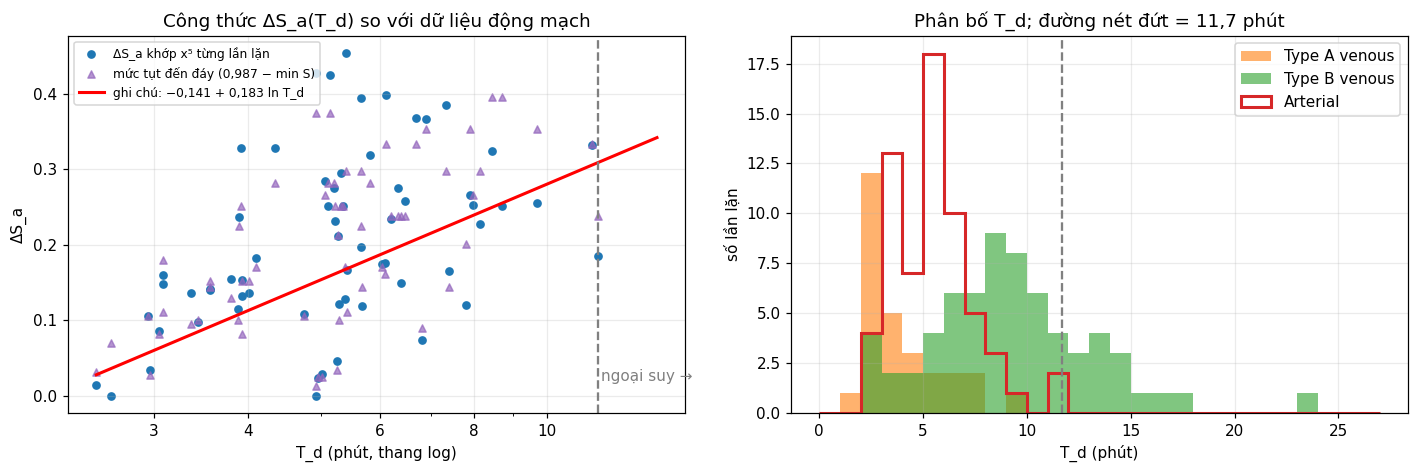

In [5]:
rows = []
for ref, g in A[A["phase"] == "dive"].groupby("ref"):
    if len(g) < 10:
        continue
    Td = g["Td"].iloc[0]; x = g["x"].values; y = g["S"].values
    r_ = least_squares(lambda p: S_DIVE0 - p[0] * x**K_EXP - y, [0.2], bounds=(0, 0.9))
    rows.append({"ref": ref, "Td": Td, "dSa_x5": r_.x[0], "drop_min": S_DIVE0 - y.min()})
P = pd.DataFrame(rows)
lnT = np.log(P["Td"])
b_x5  = np.polyfit(lnT, P["dSa_x5"], 1)
b_min = np.polyfit(lnT, P["drop_min"], 1)
print(f"Ghi chú            : ΔS_a = -0.141 + 0.183 ln T_d")
print(f"Khớp x^5 từng lần  : ΔS_a = {b_x5[1]:.3f} + {b_x5[0]:.3f} ln T_d  (n={len(P)})")
print(f"Mức tụt đến đáy    : ΔS_a = {b_min[1]:.3f} + {b_min[0]:.3f} ln T_d")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
tg = np.linspace(P["Td"].min(), 14, 200)
ax[0].scatter(P["Td"], P["dSa_x5"], s=22, color="tab:blue", label="ΔS_a khớp x⁵ từng lần lặn")
ax[0].scatter(P["Td"], P["drop_min"], s=22, marker="^", color="tab:purple", alpha=0.7, label="mức tụt đến đáy (0,987 − min S)")
ax[0].plot(tg, delta_Sa(tg), "r-", lw=2, label="ghi chú: −0,141 + 0,183 ln T_d")
ax[0].axvline(TD_MAX_ART, color="gray", ls="--"); ax[0].text(TD_MAX_ART + 0.1, 0.02, "ngoại suy →", color="gray")
ax[0].set(xscale="log", xlabel="T_d (phút, thang log)", ylabel="ΔS_a", title="Công thức ΔS_a(T_d) so với dữ liệu động mạch")
ax[0].set_xticks([3, 4, 6, 8, 10]); ax[0].xaxis.set_major_formatter(ScalarFormatter())
ax[0].legend(fontsize=8)

bins = np.arange(0, 28, 1.0)
for grp in ["Type A venous", "Type B venous"]:
    ax[1].hist(dv.loc[dv["group"] == grp, "Td"], bins=bins, alpha=0.6, color=COL[grp], label=grp)
ax[1].hist(dv.loc[dv["site"] == "arterial", "Td"], bins=bins, histtype="step", lw=2, color=COL["Arterial"], label="Arterial")
ax[1].axvline(TD_MAX_ART, color="gray", ls="--")
ax[1].set(xlabel="T_d (phút)", ylabel="số lần lặn", title="Phân bố T_d; đường nét đứt = 11,7 phút")
ax[1].legend()
plt.tight_layout(); save_show("fig_delta_Sa_check")

### 3c. Ước lượng $\tau_a$ và đánh giá $S_a(t)$

Bước này ước lượng $\tau_a$ bằng bình phương tối thiểu trên toàn bộ mẫu động mạch, bootstrap theo lần lặn lấy khoảng tin cậy, rồi đo sai số $S_a$ theo từng pha (RMSE ở đây là **trong mẫu**).

In [6]:
if TAU_A is None:
    f = lambda p: Sa_template(A["t_min"], A["Td"], p[0]) - A["S"]
    TAU_A_FIT = float(least_squares(f, [1.0], bounds=(0.05, 30)).x[0])
    # khoảng tin cậy bootstrap theo lần lặn
    rng = np.random.default_rng(SEED)
    by = {k: v for k, v in A.groupby("ref")}; ids_a = np.array(list(by))
    bt = []
    for _ in range(N_BOOT):
        fr = pd.concat([by[i] for i in rng.choice(ids_a, len(ids_a), replace=True)])
        bt.append(least_squares(lambda p: Sa_template(fr["t_min"], fr["Td"], p[0]) - fr["S"], [1.0], bounds=(0.05, 30)).x[0])
    tau_ci = np.percentile(bt, [2.5, 97.5])
    print(f"τ_a ước lượng = {TAU_A_FIT:.3f} phút  (KTC 95 % bootstrap: {tau_ci[0]:.2f}–{tau_ci[1]:.2f})")
else:
    TAU_A_FIT, tau_ci = float(TAU_A), (np.nan, np.nan)
    print(f"τ_a đặt tay = {TAU_A_FIT} phút")
TAU = TAU_A_FIT

A["pred"] = Sa_template(A["t_min"], A["Td"], TAU)
A["res"]  = A["S"] - A["pred"]
rmse = lambda x: float(np.sqrt(np.mean(np.square(x))))
print("\nSai số S_a theo pha (quan sát − mô hình):")
display(A.groupby("phase")["res"].agg(n="size", bias="mean", rmse=rmse).round(4))

τ_a ước lượng = 1.578 phút  (KTC 95 % bootstrap: 1.35–2.02)

Sai số S_a theo pha (quan sát − mô hình):


,n,bias,rmse
phase,,,
dive,2642,-0.0028,0.0423
post,1828,-0.0240,0.0639
pre,1773,-0.0244,0.0329


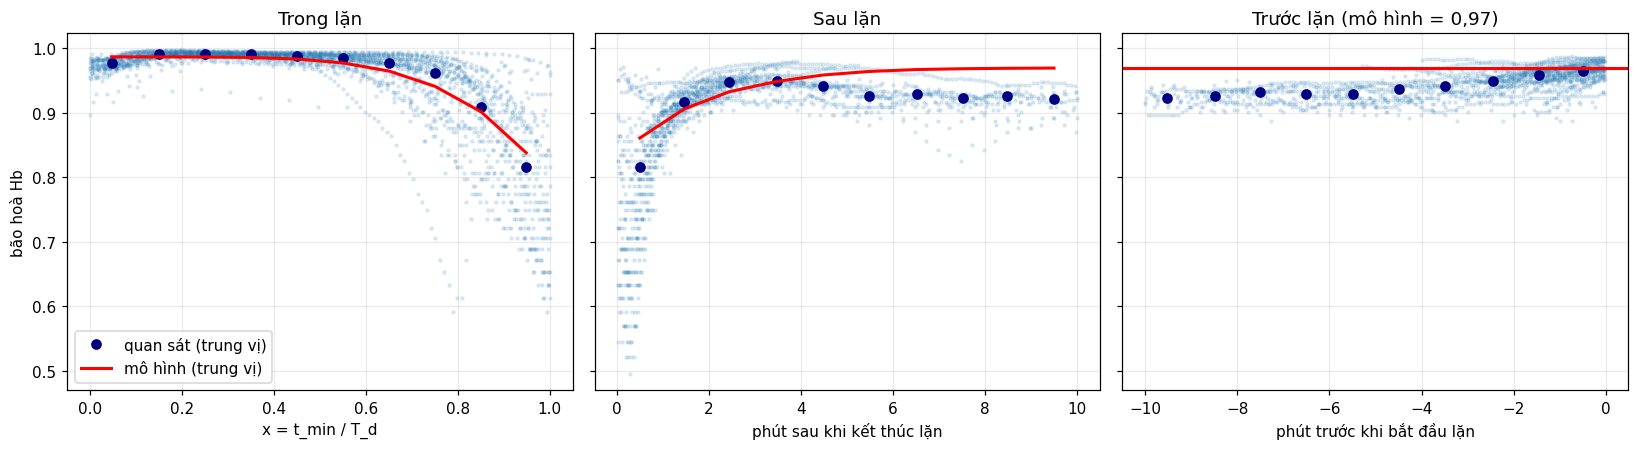

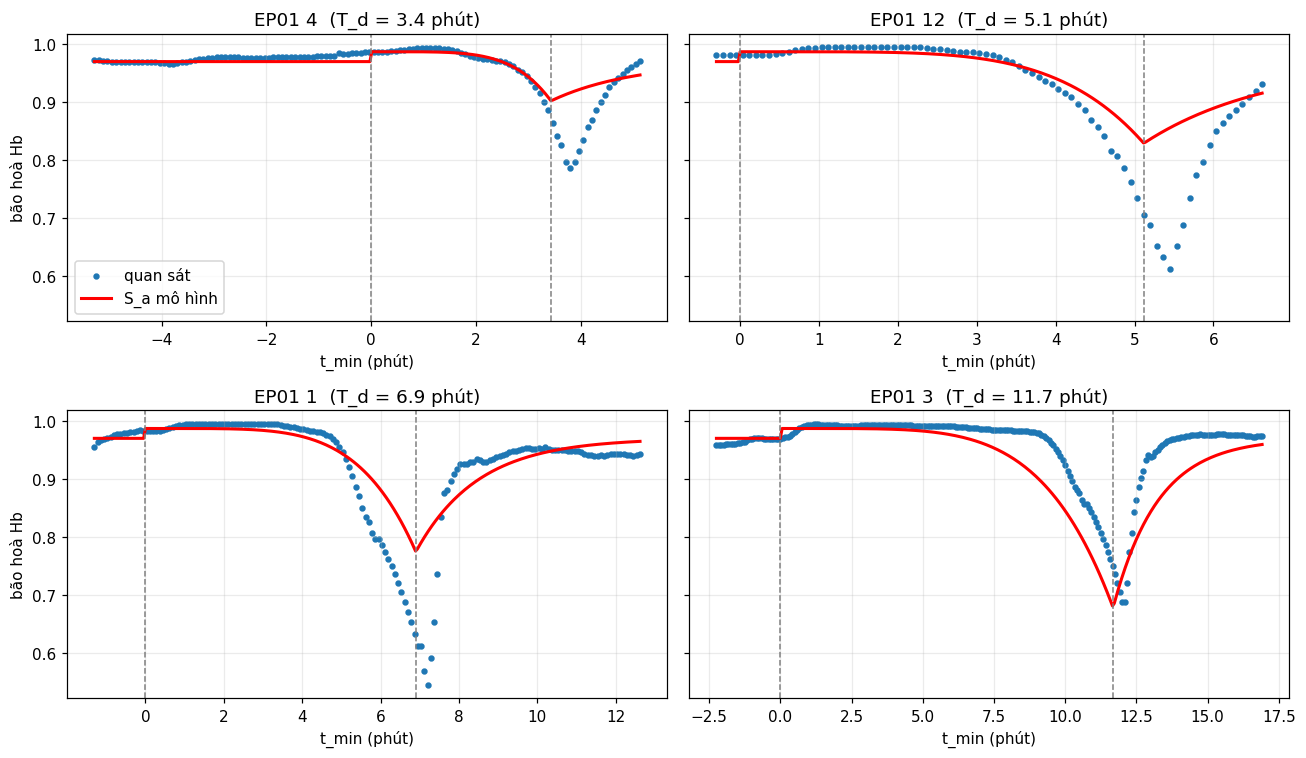

In [7]:
def binned_median(x, y, edges, min_n=5):
    x, y = np.asarray(x), np.asarray(y)
    idx = np.digitize(x, edges) - 1
    xs, ys = [], []
    for b in range(len(edges) - 1):
        m = idx == b
        if m.sum() >= min_n:
            xs.append(np.median(x[m])); ys.append(np.median(y[m]))
    return np.array(xs), np.array(ys)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
d = A[A["phase"] == "dive"]
ax[0].scatter(d["x"], d["S"], s=4, alpha=0.12, color="tab:blue")
bx, by_ = binned_median(d["x"], d["S"], np.linspace(0, 1, 11)); ax[0].plot(bx, by_, "o", color="navy", label="quan sát (trung vị)")
bx, bp = binned_median(d["x"], d["pred"], np.linspace(0, 1, 11)); ax[0].plot(bx, bp, "r-", lw=2, label="mô hình (trung vị)")
ax[0].set(title="Trong lặn", xlabel="x = t_min / T_d", ylabel="bão hoà Hb"); ax[0].legend()

p_ = A[A["phase"] == "post"]; u = p_["t_min"] - p_["Td"]; e = np.linspace(0, POST_MAX_MIN, 11)
ax[1].scatter(u, p_["S"], s=4, alpha=0.12, color="tab:blue")
bx, by_ = binned_median(u, p_["S"], e); ax[1].plot(bx, by_, "o", color="navy")
bx, bp = binned_median(u, p_["pred"], e); ax[1].plot(bx, bp, "r-", lw=2)
ax[1].set(title="Sau lặn", xlabel="phút sau khi kết thúc lặn")

q = A[A["phase"] == "pre"]; e = np.linspace(-PRE_MAX_MIN, 0, 11)
ax[2].scatter(q["t_min"], q["S"], s=4, alpha=0.12, color="tab:blue")
bx, by_ = binned_median(q["t_min"], q["S"], e); ax[2].plot(bx, by_, "o", color="navy")
ax[2].axhline(S_REST, color="r", lw=2); ax[2].set(title="Trước lặn (mô hình = 0,97)", xlabel="phút trước khi bắt đầu lặn")
plt.tight_layout(); save_show("fig_Sa_by_phase")

cand = A[A["phase"] == "dive"].groupby("ref").agg(n=("t", "size"), Td=("Td", "first"))
cand = cand[cand["n"] >= 40].sort_values("Td")
pick = cand.index[np.linspace(0, len(cand) - 1, 4).astype(int)]
fig, axs = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for a, did in zip(axs.ravel(), pick):
    g = A[A["ref"] == did].sort_values("t_min"); Td = g["Td"].iloc[0]
    a.scatter(g["t_min"], g["S"], s=10, color="tab:blue", label="quan sát")
    tgrid = np.linspace(g["t_min"].min(), g["t_min"].max(), 300)
    a.plot(tgrid, Sa_template(tgrid, Td, TAU), "r-", lw=2, label="S_a mô hình")
    a.axvline(0, color="gray", ls="--", lw=1); a.axvline(Td, color="gray", ls="--", lw=1)
    a.set(title=f"{did}  (T_d = {Td:.1f} phút)", xlabel="t_min (phút)")
axs[0, 0].set_ylabel("bão hoà Hb"); axs[1, 0].set_ylabel("bão hoà Hb"); axs[0, 0].legend()
plt.tight_layout(); save_show("fig_Sa_residuals")

## 4. E2 — Phương trình chính cho $S_v(t)$

**Cài đặt.** Với $S_a$ và $r$ cố định, đầu ra $\hat S_v$ **tuyến tính** theo $\theta=(S_{init},g_{rest},g_1,\dots,g_{p2})$, vì công thức truy hồi chỉ cộng các đáp ứng bậc nhất. Notebook dùng điều này để khớp bằng bình phương tối thiểu tuyến tính có cận ($0\le g\le 0{,}9$, $0\le S_{init}\le 1$), nhanh và không kẹt cực tiểu cục bộ.

Để chắc chắn cách làm này đúng với công thức gốc, hàm `simulate_Sv` viết **đúng như ghi chú** bằng vòng lặp $S_{j+1}=S_je^{-\Delta t/r}+(1-e^{-\Delta t/r})[S_a(t_j)-g(t_j)]$, và ô kiểm thử bên dưới sinh dữ liệu từ nó rồi kiểm tra bộ khớp tìm lại đúng $\theta$.

Bước này viết bộ mô phỏng đúng theo công thức (9) và bộ khớp tuyến tính có cận, rồi kiểm tra bộ khớp tìm lại được tham số từ dữ liệu giả.

In [8]:
SEG_NAMES = {0: "g_rest", 1: "g1", 2: "g2", 3: "g3", 4: "g_p1", 5: "g_p2"}
G_COLS = list(SEG_NAMES.values())

def seg_index(t_min, Td):
    # chỉ số giai đoạn của g(t): 0 = g_rest (t<0 hoặc t > T_d+3), 1-3 = ba đoạn lặn theo x, 4 = g_p1, 5 = g_p2
    t = np.asarray(t_min, dtype=float)
    s = np.zeros(t.shape, dtype=int)
    s = np.where((t >= 0) & (t < Td / 3), 1, s)
    s = np.where((t >= Td / 3) & (t < 2 * Td / 3), 2, s)
    s = np.where((t >= 2 * Td / 3) & (t <= Td), 3, s)
    s = np.where((t > Td) & (t <= Td + 1), 4, s)
    s = np.where((t > Td + 1) & (t <= Td + 3), 5, s)
    return s

def simulate_Sv(theta, Td, r, tau_a, t0, t1):
    # Mô phỏng ĐÚNG công thức ghi chú bằng vòng lặp. theta: dict S_init và các g.
    n  = int(np.ceil((t1 - t0) / DT_MIN)) + 1
    tg = t0 + DT_MIN * np.arange(n)
    a  = np.exp(-DT_MIN / r)
    sa = Sa_template(tg, Td, tau_a)
    gv = np.array([theta.get(SEG_NAMES[k], 0.0) for k in range(6)])[seg_index(tg, Td)]
    S  = np.empty(n); S[0] = theta["S_init"]
    for j in range(n - 1):
        S[j + 1] = S[j] * a + (1 - a) * (sa[j] - gv[j])
    return tg, S

def _basis(Td, t_obs, r, tau_a, option):
    t_obs = np.asarray(t_obs, dtype=float)
    t0 = 0.0 if option == "dive" else max(-PRE_WIN_S / 60.0, float(t_obs.min()))
    t1 = float(t_obs.max())
    n  = int(np.ceil((t1 - t0) / DT_MIN)) + 1
    tg = t0 + DT_MIN * np.arange(n)
    a, c = np.exp(-DT_MIN / r), 1 - np.exp(-DT_MIN / r)
    filt = lambda u: lfilter([0.0, c], [1.0, -a], u)
    sg   = seg_index(tg, Td)
    segs = [1, 2, 3] if option == "dive" else [0, 1, 2, 3, 4, 5]
    cols = [a ** np.arange(n)] + [-filt((sg == k).astype(float)) for k in segs]
    B  = np.column_stack([np.interp(t_obs, tg, col) for col in cols])
    b0 = np.interp(t_obs, tg, filt(Sa_template(tg, Td, tau_a)))
    return B, b0, segs

def fit_dive(t_obs, y_obs, Td, r, tau_a, option="full"):
    # option 'full': 7 tham số, cửa sổ cả chu kỳ. option 'dive': S_init, g1, g2, g3, chỉ dòng trong [0, T_d].
    y = np.asarray(y_obs, dtype=float)
    B, b0, segs = _basis(Td, t_obs, r, tau_a, option)
    lo = [0.0] * (1 + len(segs)); hi = [1.0] + [G_MAX] * len(segs)
    sol = lsq_linear(B, y - b0, bounds=(lo, hi))
    theta = dict(zip(["S_init"] + [SEG_NAMES[k] for k in segs], sol.x))
    return theta, b0 + B @ sol.x

# ---- Kiểm thử: dữ liệu giả từ simulate_Sv, bộ khớp phải tìm lại đúng tham số ----
true = {"S_init": 0.62, "g_rest": 0.08, "g1": 0.15, "g2": 0.35, "g3": 0.50, "g_p1": 0.45, "g_p2": 0.20}
Td_t, r_t, tau_t = 8.0, 0.75, 1.5
tg_, S_ = simulate_Sv(true, Td_t, r_t, tau_t, -5.0, Td_t + 7.0)
t_obs = np.arange(-5.0, Td_t + 7.0, 0.25)
y_obs = np.interp(t_obs, tg_, S_)
th_f, pred_f = fit_dive(t_obs, y_obs, Td_t, r_t, tau_t, "full")
err_f = max(abs(th_f[k] - true[k]) for k in true)
m = (t_obs >= 0) & (t_obs <= Td_t)
th_d, _ = fit_dive(t_obs[m], y_obs[m], Td_t, r_t, tau_t, "dive")
tg_d, S_d = simulate_Sv({"S_init": 0.62, "g1": 0.15, "g2": 0.35, "g3": 0.50}, Td_t, r_t, tau_t, 0.0, Td_t)
y_d = np.interp(t_obs[m], tg_d, S_d)
th_d, _ = fit_dive(t_obs[m], y_d, Td_t, r_t, tau_t, "dive")
err_d = max(abs(th_d[k] - v) for k, v in {"S_init": 0.62, "g1": 0.15, "g2": 0.35, "g3": 0.50}.items())
print(f"Kiểm thử cả chu kỳ : sai số tham số lớn nhất = {err_f:.2e}")
print(f"Kiểm thử chỉ lặn   : sai số tham số lớn nhất = {err_d:.2e}")
assert err_f < 1e-4 and err_d < 1e-4, "Bộ khớp không tìm lại được tham số gốc!"

Kiểm thử cả chu kỳ : sai số tham số lớn nhất = 7.77e-16
Kiểm thử chỉ lặn   : sai số tham số lớn nhất = 3.33e-16


## 5. Cửa sổ khớp và cửa sổ sạch

Mỗi lần lặn tĩnh mạch có cửa sổ $[t_{start}-300\,\mathrm{s},\;t_{end}+420\,\mathrm{s}]$ cùng chim và cùng site. Cửa sổ **sạch** là cửa sổ không chứa lần lặn nào khác (kể cả đợt lặn `unlisted_dive` không có trong bảng và các lần lặn không có mẫu). Ghi chú cũng dự đoán type A thường không có cửa sổ sạch vì lặn liên tiếp, ô dưới kiểm tra điều đó.

Bước này dựng cửa sổ khớp cho từng cú lặn tĩnh mạch, đánh dấu cửa sổ sạch, và đếm số dòng trong từng giai đoạn của $g(t)$ để biết tham số nào có đủ dữ liệu.

Lần lặn không có mẫu (kiểm tra chồng lấn theo giờ trong ngày): ['EP36A 8', 'EP07 9', 'EP07 10']


,so_lan_lan,cua_so_sach,co_lan_lan_khac,co_unlisted,du_dieu_kien_ca_chu_ky,du_dieu_kien_chi_lan,bi_loai_it_diem,canh_bao_it_diem
group,,,,,,,,
Type A venous,28,3,24,7,3,18,10,7
Type B venous,65,28,29,17,28,61,4,2


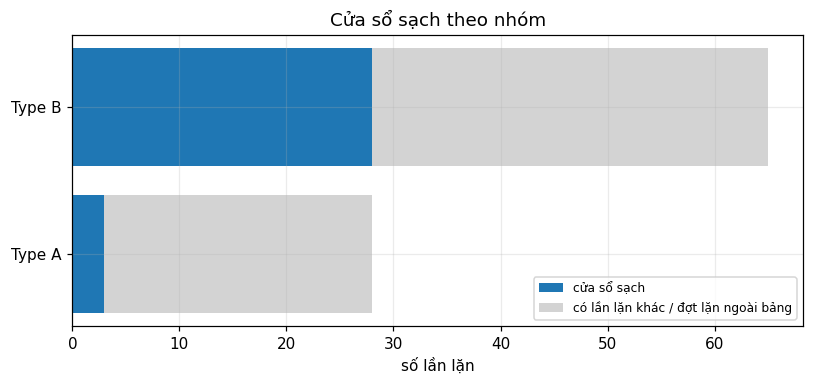

In [9]:
all_dv = ts[ts["dive_id"].notna()].groupby("dive_id").agg(
    bird=("bird", "first"), site=("site", "first"), t_start=("t_start", "first"), Td=("dive_dur_min", "first"))
all_dv["t_end"] = all_dv["t_start"] + 60.0 * all_dv["Td"]
no_rows = dives[~dives["dive_id"].isin(all_dv.index)]          # lần lặn không có mẫu: chỉ biết giờ trong ngày
print("Lần lặn không có mẫu (kiểm tra chồng lấn theo giờ trong ngày):", no_rows["dive_id"].tolist())

def get_window(did):
    d = dv.loc[did]
    W0, W1 = d["t_start"] - PRE_WIN_S, d["t_end"] + POST_WIN_S
    g = ts[(ts["bird"] == d["bird"]) & (ts["site"] == d["site"]) & (ts["t"] >= W0) & (ts["t"] <= W1)].copy()
    g["t_min"] = (g["t"] - d["t_start"]) / 60.0
    oth = all_dv[(all_dv["bird"] == d["bird"]) & (all_dv["site"] == d["site"]) & (all_dv.index != did)]
    other = bool(((oth["t_start"] < W1) & (oth["t_end"] > W0)).any())
    for m in no_rows[no_rows["bird"] == d["bird"]].itertuples():
        if m.start < (W1 % 86400) and m.end > (W0 % 86400):
            other = True
    unl = bool(g["unlisted_dive"].any())
    return g, other, unl

ven = dv[dv["site"] == "venous"].copy()
WIN, rows = {}, []
for did, d in ven.iterrows():
    g, other, unl = get_window(did)
    WIN[did] = g
    sc = np.bincount(seg_index(g["t_min"], d["Td"]), minlength=6)
    inwin = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
    rows.append({"dive_id": did, "group": d["group"], "Td": d["Td"], "n_window": len(g), "other_dive": other, "unlisted": unl,
                 "n_dive_rows": len(inwin), **{f"n_{SEG_NAMES[k]}": sc[k] for k in range(6)}})
W = pd.DataFrame(rows).set_index("dive_id")
W["clean"] = ~W["other_dive"] & ~W["unlisted"]
W["ok_full"] = W["clean"] & (W["n_window"] >= MIN_ROWS_FULL) & (W[[f"n_{n}" for n in G_COLS]].min(axis=1) >= MIN_PER_SEG)
thirds = W[["n_g1", "n_g2", "n_g3"]].min(axis=1)
W["ok_dive"] = (W["n_dive_rows"] >= MIN_ROWS_DIVE) & (thirds >= MIN_PER_SEG)
W["dive_low_n"] = (W["n_dive_rows"] < MIN_ROWS_DIVE) & (thirds >= MIN_PER_SEG)   # bị loại vì quá ít điểm cho 4 tham số
W["few_points"] = W["ok_dive"] & (W["n_dive_rows"] < LOW_N_WARN)                  # được giữ, gắn cờ cảnh báo

summary = W.groupby("group").agg(so_lan_lan=("Td", "size"), cua_so_sach=("clean", "sum"), co_lan_lan_khac=("other_dive", "sum"),
                                 co_unlisted=("unlisted", "sum"), du_dieu_kien_ca_chu_ky=("ok_full", "sum"), du_dieu_kien_chi_lan=("ok_dive", "sum"),
                                 bi_loai_it_diem=("dive_low_n", "sum"), canh_bao_it_diem=("few_points", "sum"))
display(summary)

fig, ax = plt.subplots(1, 1, figsize=(7.5, 3.6))
lab = {"clean": "cửa sổ sạch", "dirty": "có lần lặn khác / đợt lặn ngoài bảng"}
for k, grp in enumerate(["Type A venous", "Type B venous"]):
    s = W[W["group"] == grp]
    ax.barh(k, s["clean"].sum(), color="tab:blue", label=lab["clean"] if k == 0 else None)
    ax.barh(k, (~s["clean"]).sum(), left=s["clean"].sum(), color="lightgray", label=lab["dirty"] if k == 0 else None)
ax.set_yticks([0, 1]); ax.set_yticklabels(["Type A", "Type B"]); ax.set_xlabel("số lần lặn"); ax.set_title("Cửa sổ sạch theo nhóm"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); save_show("fig_windows")

## 6. Chọn $r=V_v/Q$

Ghi chú không cho giá trị $r$. Vì $r$ quyết định tốc độ $S_v$ đuổi theo $S_a-g$, nó được xác định rõ từ các đoạn chuyển tiếp (sau lặn) của các cửa sổ sạch. Ô dưới quét $r$ và chọn giá trị làm tổng sai số của phương án **cả chu kỳ** nhỏ nhất.

Bước này quét $r$ trên các cửa sổ sạch và chọn giá trị làm sai số gộp nhỏ nhất. Giá trị này (`R`) dùng cho các bước **mô tả trong mẫu**. Với kiểm định ngoài mẫu, $r$ phải được chọn lại mà không có chim bị bỏ (mục 6b).

r ước lượng = 0.764 phút (RMSE gộp 0.0666, trên 31 cửa sổ sạch)


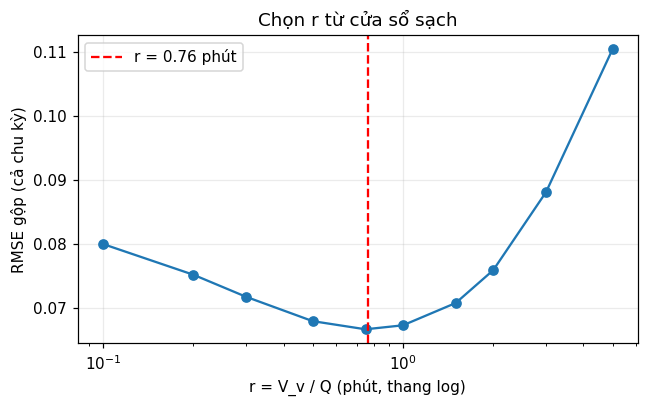

In [10]:
ids_full = W.index[W["ok_full"]].tolist()
assert len(ids_full) >= 5, "Quá ít cửa sổ sạch để ước lượng r"

def total_rmse(r, ids):
    sse, n = 0.0, 0
    for did in ids:
        g = WIN[did]; _, pred = fit_dive(g["t_min"], g["Hb"], ven.loc[did, "Td"], r, TAU, "full")
        sse += np.sum((g["Hb"].values - pred) ** 2); n += len(g)
    return np.sqrt(sse / n)

grid = np.array([0.1, 0.2, 0.3, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 5.0])
prof = np.array([total_rmse(r, ids_full) for r in grid])
if R_VEN is None:
    opt = minimize_scalar(lambda r: total_rmse(r, ids_full), bounds=(0.2, 3.0), method="bounded")
    R = float(opt.x)
    print(f"r ước lượng = {R:.3f} phút (RMSE gộp {opt.fun:.4f}, trên {len(ids_full)} cửa sổ sạch)")
else:
    R = float(R_VEN); print(f"r đặt tay = {R} phút")

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(grid, prof, "o-"); ax.axvline(R, color="r", ls="--", label=f"r = {R:.2f} phút")
ax.set(xscale="log", xlabel="r = V_v / Q (phút, thang log)", ylabel="RMSE gộp (cả chu kỳ)", title="Chọn r từ cửa sổ sạch"); ax.legend()
plt.tight_layout(); save_show("fig_choose_r")

### 6b. Chọn $r$ lồng nhau (leave-one-bird-out)

Bước này chuẩn bị giá trị $r$ **không bị rò rỉ** cho kiểm định ngoài mẫu. $r$ ở mục 6 được chọn bằng cách làm RMSE nhỏ nhất trên *mọi* cửa sổ sạch, trong đó có cả chim sẽ bị giữ lại để đánh giá. Với mỗi chim bị bỏ, $r$ được chọn lại chỉ từ các cửa sổ sạch của các chim còn lại (`R_NESTED`). Để tránh khớp lại nhiều lần, SSE của từng cửa sổ sạch được tính một lần trên lưới $r$ rồi cộng theo nhóm chim.

r toàn bộ dữ liệu: liên tục = 0.764, trên lưới = 0.734  |  31 cửa sổ sạch từ 8 chim
r chọn khi bỏ từng chim (lồng nhau): {'EP04': 0.734, 'EP05': 0.928, 'EP07': 0.734, 'EP17': 0.826, 'EP19': 0.734, 'EP20': 0.734, 'EP36': 0.734, 'EP37': 0.826, 'EP40': 0.734, 'EP48': 0.734}
khoảng r lồng nhau: 0.73–0.93 phút


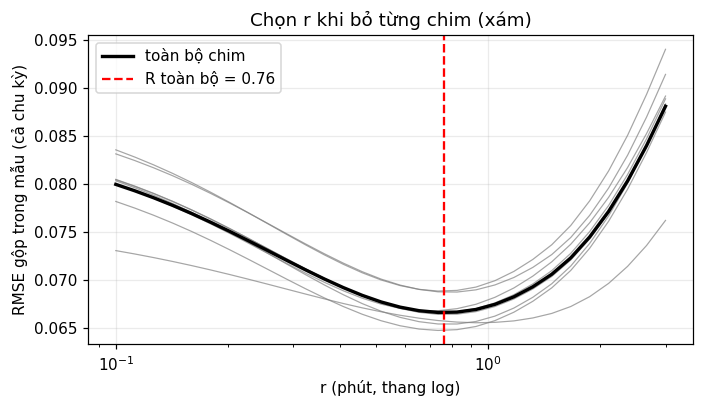

In [11]:
SSE_ROWS = []
for did in ids_full:
    g_ = WIN[did]; Td_ = ven.loc[did, "Td"]; bird_ = ven.loc[did, "bird"]
    for r_ in R_GRID:
        _, pred_ = fit_dive(g_["t_min"], g_["Hb"], Td_, r_, TAU, "full")
        SSE_ROWS.append({"dive_id": did, "bird": bird_, "r": r_, "sse": float(np.sum((g_["Hb"].values - pred_) ** 2)), "n": len(g_)})
SSE_TAB = pd.DataFrame(SSE_ROWS)

def pick_r(exclude_bird=None):
    # r làm RMSE gộp nhỏ nhất trên các cửa sổ sạch, bỏ chim `exclude_bird`
    t = SSE_TAB if exclude_bird is None else SSE_TAB[SSE_TAB["bird"] != exclude_bird]
    agg = t.groupby("r")[["sse", "n"]].sum()
    rm = np.sqrt(agg["sse"] / agg["n"])
    return float(rm.idxmin()), rm

R_GRID_BEST, rm_all = pick_r()
BIRDS_VEN = sorted(ven["bird"].unique())
R_NESTED = {b: pick_r(b)[0] for b in BIRDS_VEN}
print(f"r toàn bộ dữ liệu: liên tục = {R:.3f}, trên lưới = {R_GRID_BEST:.3f}  |  {SSE_TAB['dive_id'].nunique()} cửa sổ sạch từ {SSE_TAB['bird'].nunique()} chim")
print("r chọn khi bỏ từng chim (lồng nhau):", {b: round(v, 3) for b, v in R_NESTED.items()})
print(f"khoảng r lồng nhau: {min(R_NESTED.values()):.2f}–{max(R_NESTED.values()):.2f} phút")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for b in SSE_TAB["bird"].unique():
    _, rm_b = pick_r(b); ax.plot(rm_b.index, rm_b.values, color="gray", lw=0.8, alpha=0.7)
ax.plot(rm_all.index, rm_all.values, "k-", lw=2.2, label="toàn bộ chim")
ax.axvline(R, color="r", ls="--", label=f"R toàn bộ = {R:.2f}")
ax.set(xscale="log", xlabel="r (phút, thang log)", ylabel="RMSE gộp trong mẫu (cả chu kỳ)", title="Chọn r khi bỏ từng chim (xám)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/fig_nested_r.png", dpi=140); plt.show()
pd.Series(R_NESTED, name="r_chon_khi_bo_chim").rename_axis("bird").reset_index().to_csv(f"{RES_DIR}/nested_r_by_bird.csv", index=False)

## 7. Khớp từng lần lặn

- **Cả chu kỳ:** cửa sổ sạch, 7 tham số $(S_{init},g_{rest},g_1,g_2,g_3,g_{p1},g_{p2})$.
- **Chỉ lặn:** các dòng trong $[0,T_d]$, 4 tham số $(S_{init},g_1,g_2,g_3)$; dùng được cho cả type A (phần lớn không có cửa sổ sạch).

Bước này khớp từng cú lặn. Mọi RMSE/R² ở mục này là **trong mẫu** (tham số và sai số tính trên cùng dữ liệu), nên chỉ mô tả mức khớp, không đo khả năng dự báo.

In [12]:
def run_fits(option, ids):
    out = []
    for did in ids:
        d = ven.loc[did]; g = WIN[did]
        if option == "dive":
            g = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
        th, pred = fit_dive(g["t_min"], g["Hb"], d["Td"], R, TAU, option)
        out.append({"dive_id": did, "bird": d["bird"], "group": d["group"], "Td": d["Td"], "z_max": d["z_max"],
                    "extrapolated": bool(d["Td"] > TD_MAX_ART), "n_rows": len(g),
                    "rmse_trong_mau": rmse(g["Hb"].values - pred),
                    "r2_trong_mau": 1 - float(np.sum((g["Hb"].values - pred) ** 2) / np.sum((g["Hb"].values - g["Hb"].mean()) ** 2)),
                    "warn_n": bool(W.loc[did, "few_points"]), **th})
    return pd.DataFrame(out).set_index("dive_id")

F = run_fits("full", W.index[W["ok_full"]])
G = run_fits("dive", W.index[W["ok_dive"]])
print(f"Cả chu kỳ: {len(F)} lần lặn {F['group'].value_counts().to_dict()}")
print(f"Chỉ lặn  : {len(G)} lần lặn {G['group'].value_counts().to_dict()}  (MIN_ROWS_DIVE = {MIN_ROWS_DIVE}; {int(G['warn_n'].sum())} lần gắn cờ ít điểm < {LOW_N_WARN})")

print("\nCả chu kỳ: trung vị tham số theo nhóm (RMSE, R² là TRONG MẪU)")
display(F.groupby("group")[["n_rows", "rmse_trong_mau", "r2_trong_mau", "S_init"] + G_COLS].median().round(3))
print("Chỉ lặn: trung vị tham số theo nhóm (RMSE, R² là TRONG MẪU)")
display(G.groupby("group")[["n_rows", "rmse_trong_mau", "r2_trong_mau", "S_init", "g1", "g2", "g3"]].median().round(3))

for name, T in [("cả chu kỳ", F), ("chỉ lặn", G)]:
    cols = [c for c in G_COLS if c in T.columns]
    lo = {c: round(float((T[c] < 1e-6).mean()), 2) for c in cols}; hi = {c: round(float((T[c] > G_MAX - 1e-6).mean()), 2) for c in cols}
    print(f"Tỉ lệ tham số chạm cận ({name}) - cận 0: {lo} | cận {G_MAX}: {hi}")

Cả chu kỳ: 31 lần lặn {'Type B venous': 28, 'Type A venous': 3}
Chỉ lặn  : 79 lần lặn {'Type B venous': 61, 'Type A venous': 18}  (MIN_ROWS_DIVE = 12; 9 lần gắn cờ ít điểm < 20)

Cả chu kỳ: trung vị tham số theo nhóm (RMSE, R² là TRONG MẪU)


,n_rows,rmse_trong_mau,r2_trong_mau,S_init,g_rest,g1,g2,g3,g_p1,g_p2
group,,,,,,,,,,
Type A venous,73.0,0.07,0.793,0.654,0.193,0.000,0.000,0.559,0.375,0.090
Type B venous,85.0,0.06,0.847,0.645,0.258,0.522,0.536,0.417,0.462,0.187


Chỉ lặn: trung vị tham số theo nhóm (RMSE, R² là TRONG MẪU)


,n_rows,rmse_trong_mau,r2_trong_mau,S_init,g1,g2,g3
group,,,,,,,
Type A venous,23.5,0.025,0.873,0.845,0.00,0.054,0.146
Type B venous,40.0,0.048,0.833,0.818,0.38,0.483,0.422


Tỉ lệ tham số chạm cận (cả chu kỳ) - cận 0: {'g_rest': 0.0, 'g1': 0.06, 'g2': 0.06, 'g3': 0.0, 'g_p1': 0.03, 'g_p2': 0.1} | cận 0.9: {'g_rest': 0.0, 'g1': 0.03, 'g2': 0.0, 'g3': 0.0, 'g_p1': 0.0, 'g_p2': 0.0}
Tỉ lệ tham số chạm cận (chỉ lặn) - cận 0: {'g1': 0.11, 'g2': 0.08, 'g3': 0.08} | cận 0.9: {'g1': 0.01, 'g2': 0.0, 'g3': 0.0}


## 8. Biểu đồ

Các ô dưới: (a), (b) đường khớp kèm **panel phần dư** và hệ số tự tương quan lag-1; đường $S_v$ được **cắt tại 0** khi vẽ; (c) quan sát so với mô hình và phân bố RMSE trong mẫu; (d) $g$ theo giai đoạn; (e) $g$ theo $T_d$, $z_{max}$; (f) so hai phương án.

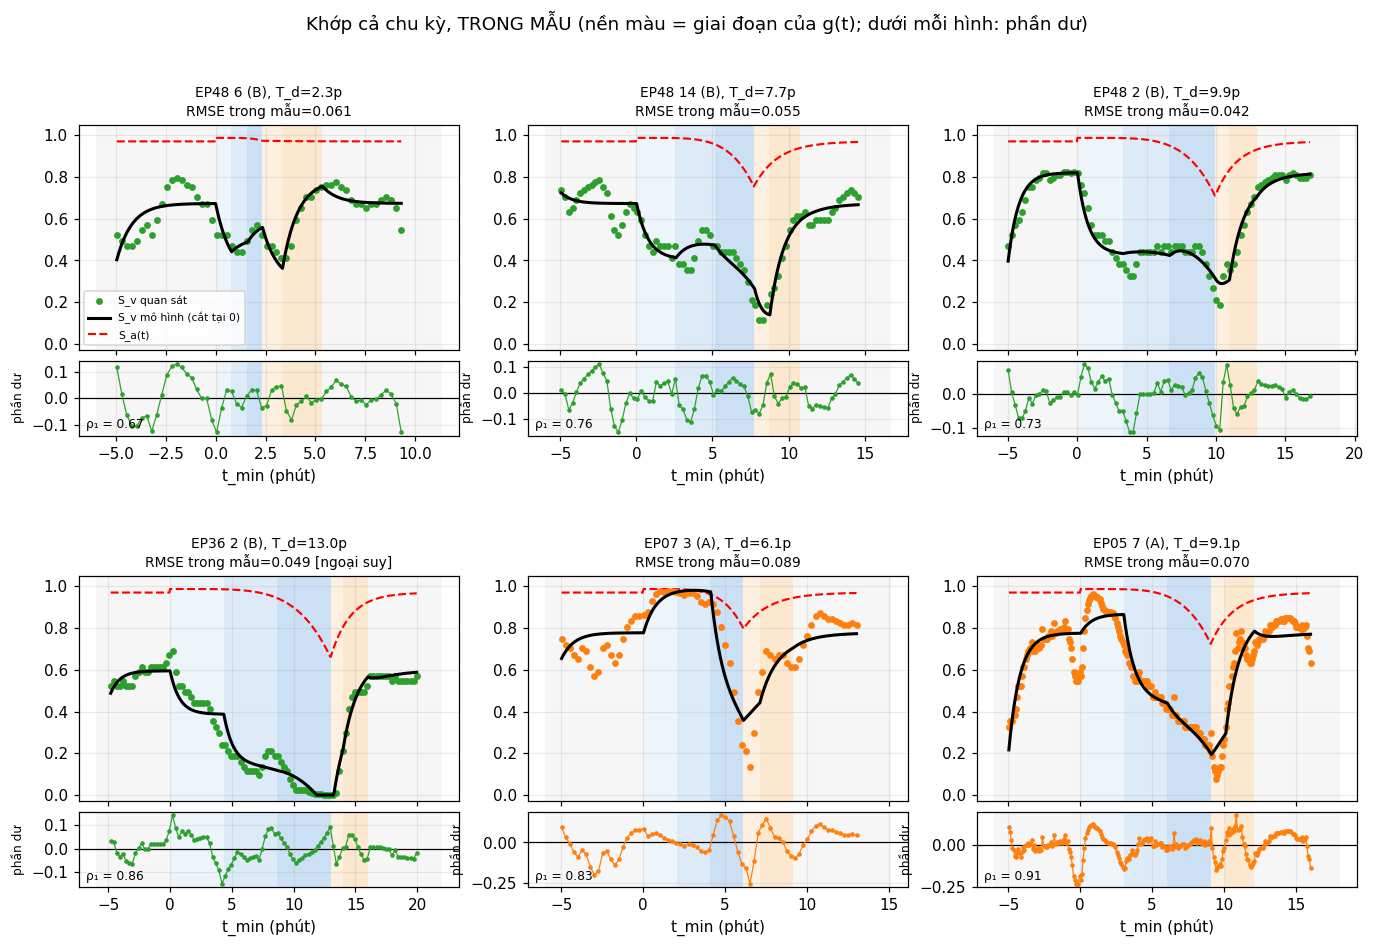

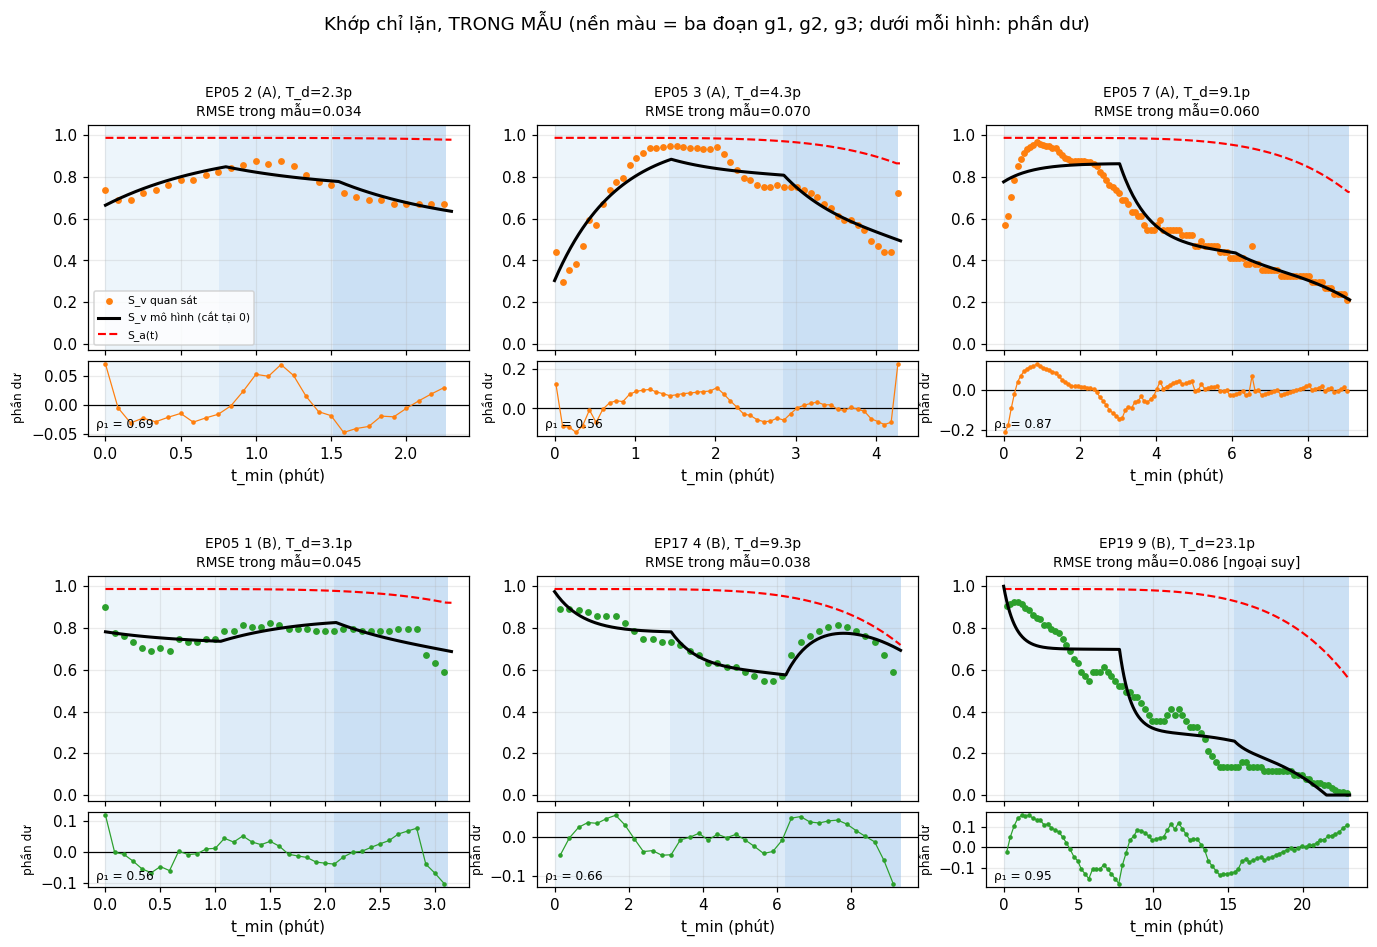

In [13]:
SEG_COL = {0: "#eeeeee", 1: "#dcecf9", 2: "#bcd9f2", 3: "#98c3ea", 4: "#fde3c4", 5: "#fbd0a0"}

def fit_pack(did, option):
    # Gom mọi thứ cần để vẽ/đánh giá một lần khớp: dữ liệu trong cửa sổ, tham số, đường mô phỏng, giá trị mô hình tại điểm đo.
    d = ven.loc[did]; Td = d["Td"]; g = WIN[did]
    T = F if option == "full" else G
    if option == "dive":
        g = g[(g["t_min"] >= 0) & (g["t_min"] <= Td)]
        t0, t1 = 0.0, Td
    else:
        t0, t1 = max(-PRE_WIN_S / 60, g["t_min"].min()), g["t_min"].max()
    th = T.loc[did, [c for c in ["S_init"] + G_COLS if c in T.columns]].to_dict()
    tg_, Sv_ = simulate_Sv(th, Td, R, TAU, t0, t1)
    pred = np.interp(g["t_min"].values, tg_, Sv_)
    return d, Td, g, T, tg_, Sv_, pred

def lag1(res):
    res = np.asarray(res, float)
    if len(res) < 8: return np.nan
    r_ = res - res.mean(); den = np.sum(r_ * r_)
    return float(np.sum(r_[:-1] * r_[1:]) / den) if den > 0 else np.nan

def plot_fit(fig, spec, did, option):
    d, Td, g, T, tg_, Sv_, pred = fit_pack(did, option)
    gs = spec.subgridspec(2, 1, height_ratios=[3, 1], hspace=0.07)
    a = fig.add_subplot(gs[0]); ar = fig.add_subplot(gs[1], sharex=a)
    if option == "full":
        for k, (lo_, hi_) in {0: (-6, 0), 1: (0, Td/3), 2: (Td/3, 2*Td/3), 3: (2*Td/3, Td), 4: (Td, Td+1), 5: (Td+1, Td+3), 6: (Td+3, Td+9)}.items():
            for ax_ in (a, ar): ax_.axvspan(lo_, hi_, color=SEG_COL.get(k if k < 6 else 0), alpha=0.5, lw=0)
    else:
        for k, (lo_, hi_) in {1: (0, Td/3), 2: (Td/3, 2*Td/3), 3: (2*Td/3, Td)}.items():
            for ax_ in (a, ar): ax_.axvspan(lo_, hi_, color=SEG_COL[k], alpha=0.5, lw=0)
    a.scatter(g["t_min"], g["Hb"], s=12, color=COL[d["group"]], zorder=3, label="S_v quan sát")
    a.plot(tg_, np.maximum(Sv_, 0.0), "k-", lw=2, zorder=4, label="S_v mô hình (cắt tại 0)")   # S_v < 0 vô lý về sinh lý
    a.plot(tg_, Sa_template(tg_, Td, TAU), "r--", lw=1.4, zorder=2, label="S_a(t)")
    flag = " [ngoại suy]" if d["extrapolated"] else ""
    a.set_title(f"{did} ({d['group'].split()[1]}), T_d={Td:.1f}p\nRMSE trong mẫu={T.loc[did, 'rmse_trong_mau']:.3f}{flag}", fontsize=9)
    a.set_ylim(-0.03, 1.05); plt.setp(a.get_xticklabels(), visible=False)
    res = g["Hb"].values - pred                                 # phần dư theo mô hình chưa cắt (đúng đại lượng đã khớp)
    ar.axhline(0, color="k", lw=0.8); ar.plot(g["t_min"], res, ".-", color=COL[d["group"]], lw=0.8, ms=4)
    ar.text(0.02, 0.06, f"ρ₁ = {lag1(res):.2f}", transform=ar.transAxes, fontsize=8, va="bottom")
    ar.set_xlabel("t_min (phút)"); ar.set_ylabel("phần dư", fontsize=8)
    return a

def pick_spread(T, grp, k):
    s = T[T["group"] == grp].sort_values("Td")
    if len(s) == 0: return []
    return list(s.index[np.unique(np.linspace(0, len(s) - 1, min(k, len(s))).astype(int))])

def example_figure(ids_ex, option, title, fname):
    fig = plt.figure(figsize=(15, 9)); outer = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.18)
    first = None
    for k, did in enumerate(ids_ex[:6]):
        a = plot_fit(fig, outer[k // 3, k % 3], did, option); first = first or a
    first.legend(fontsize=7, loc="lower left"); fig.suptitle(title, y=0.995)
    fig.savefig(f"{IMG_DIR}/{fname}", dpi=140, bbox_inches="tight"); plt.show()

# (a) ví dụ cả chu kỳ: 4 type B (trải theo T_d) + type A nếu có
example_figure(pick_spread(F, "Type B venous", 4) + pick_spread(F, "Type A venous", 2), "full",
               "Khớp cả chu kỳ, TRONG MẪU (nền màu = giai đoạn của g(t); dưới mỗi hình: phần dư)", "fig_fit_full_cycle_residuals.png")
# (b) ví dụ chỉ lặn: 3 type A + 3 type B
example_figure(pick_spread(G, "Type A venous", 3) + pick_spread(G, "Type B venous", 3), "dive",
               "Khớp chỉ lặn, TRONG MẪU (nền màu = ba đoạn g1, g2, g3; dưới mỗi hình: phần dư)", "fig_fit_dive_only_residuals.png")

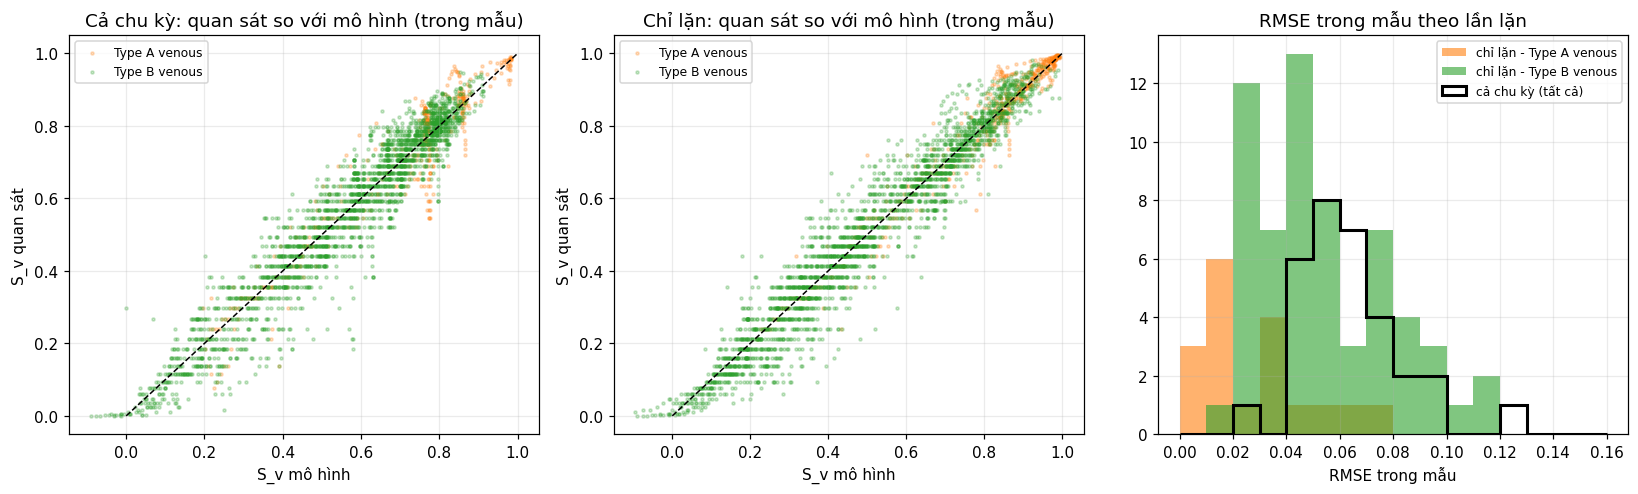

In [14]:
# (c) chất lượng khớp: quan sát so với mô hình và phân bố RMSE
def collect(option, ids):
    out = []
    for did in ids:
        d = ven.loc[did]; g = WIN[did]
        if option == "dive": g = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
        T = F if option == "full" else G
        th, pred = fit_dive(g["t_min"], g["Hb"], d["Td"], R, TAU, option)
        out.append(pd.DataFrame({"dive_id": did, "group": d["group"], "obs": g["Hb"].values, "pred": pred}))
    return pd.concat(out)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.6))
for k, (name, T, opt) in enumerate([("Cả chu kỳ", F, "full"), ("Chỉ lặn", G, "dive")]):
    P_ = collect(opt, T.index)
    for grp in ["Type A venous", "Type B venous"]:
        s = P_[P_["group"] == grp]; ax[k].scatter(s["pred"], s["obs"], s=4, alpha=0.25, color=COL[grp], label=grp)
    ax[k].plot([0, 1], [0, 1], "k--", lw=1); ax[k].set(title=f"{name}: quan sát so với mô hình (trong mẫu)", xlabel="S_v mô hình", ylabel="S_v quan sát"); ax[k].legend(fontsize=8)
bins = np.linspace(0, 0.16, 17)
for grp in ["Type A venous", "Type B venous"]:
    ax[2].hist(G.loc[G["group"] == grp, "rmse_trong_mau"], bins=bins, alpha=0.6, color=COL[grp], label=f"chỉ lặn - {grp}")
ax[2].hist(F["rmse_trong_mau"], bins=bins, histtype="step", lw=2, color="k", label="cả chu kỳ (tất cả)")
ax[2].set(title="RMSE trong mẫu theo lần lặn", xlabel="RMSE trong mẫu"); ax[2].legend(fontsize=8)
plt.tight_layout(); save_show("fig_fit_quality_in_sample")

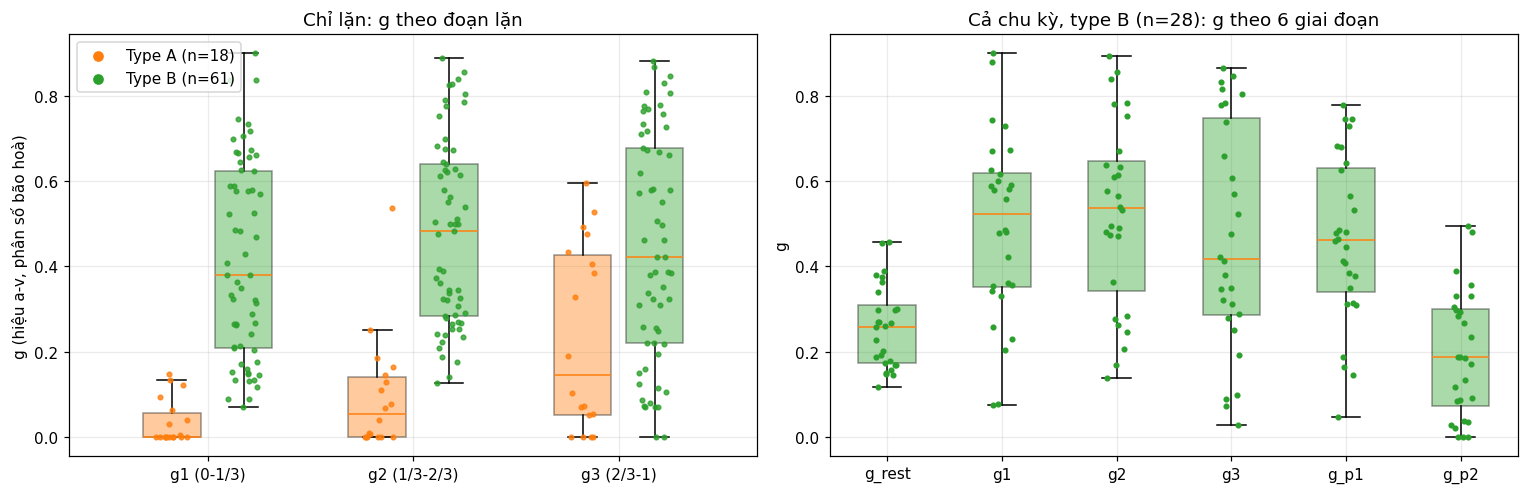

In [15]:
# (d) g theo giai đoạn: chỉ lặn (g1-g3, cả hai nhóm) và cả chu kỳ (6 giai đoạn, type B)
rng = np.random.default_rng(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for k, grp in enumerate(["Type A venous", "Type B venous"]):
    s = G[G["group"] == grp]
    for j, c in enumerate(["g1", "g2", "g3"]):
        pos = j + (k - 0.5) * 0.35
        ax[0].boxplot(s[c], positions=[pos], widths=0.28, showfliers=False, patch_artist=True, boxprops=dict(facecolor=COL[grp], alpha=0.4))
        ax[0].scatter(pos + rng.uniform(-0.08, 0.08, len(s)), s[c], s=9, color=COL[grp], alpha=0.8, zorder=3)
ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["g1 (0-1/3)", "g2 (1/3-2/3)", "g3 (2/3-1)"])
ax[0].set(ylabel="g (hiệu a-v, phân số bão hoà)", title="Chỉ lặn: g theo đoạn lặn")
ax[0].scatter([], [], color=COL["Type A venous"], label=f"Type A (n={(G['group']=='Type A venous').sum()})")
ax[0].scatter([], [], color=COL["Type B venous"], label=f"Type B (n={(G['group']=='Type B venous').sum()})"); ax[0].legend()

s = F[F["group"] == "Type B venous"]; order = ["g_rest", "g1", "g2", "g3", "g_p1", "g_p2"]
ax[1].boxplot([s[c] for c in order], showfliers=False, patch_artist=True, boxprops=dict(facecolor=COL["Type B venous"], alpha=0.4))
for j, c in enumerate(order): ax[1].scatter(j + 1 + rng.uniform(-0.1, 0.1, len(s)), s[c], s=9, color=COL["Type B venous"], zorder=3)
ax[1].set_xticks(range(1, 7)); ax[1].set_xticklabels(order)
ax[1].set(title=f"Cả chu kỳ, type B (n={len(s)}): g theo 6 giai đoạn", ylabel="g")
plt.tight_layout(); save_show("fig_g_by_phase")

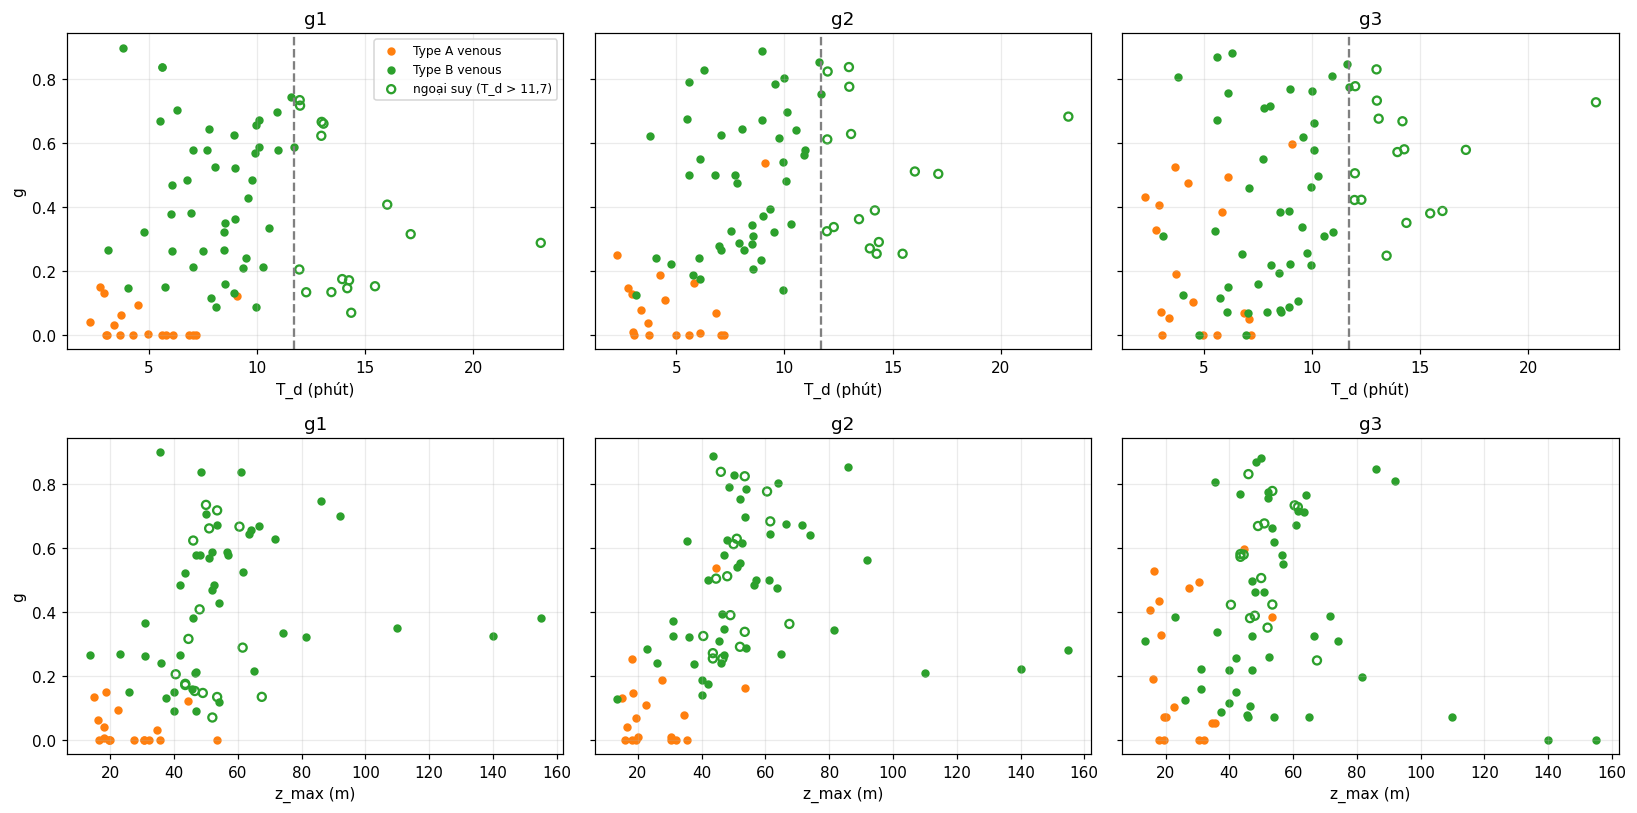

Tương quan Spearman của g với T_d và z_max (chỉ lặn, từng nhóm):


,nhóm,g,rho_Td,rho_zmax
0,Type A venous,g1,-0.26,-0.40
1,Type A venous,g2,-0.21,0.08
2,Type A venous,g3,-0.13,-0.11
3,Type B venous,g1,-0.13,0.35
4,Type B venous,g2,0.23,0.34
5,Type B venous,g3,0.32,0.13


In [16]:
# (e) g1-g3 phụ thuộc T_d và z_max (nhóm chỉ lặn); đánh dấu lần lặn ngoại suy (T_d > 11,7 phút)
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5), sharey="row")
for r_, xcol, xl in [(0, "Td", "T_d (phút)"), (1, "z_max", "z_max (m)")]:
    for c_, gc in enumerate(["g1", "g2", "g3"]):
        for grp in ["Type A venous", "Type B venous"]:
            s = G[G["group"] == grp]
            ok = s[~s["extrapolated"]]; ex = s[s["extrapolated"]]
            ax[r_, c_].scatter(ok[xcol], ok[gc], s=20, color=COL[grp], label=grp if (r_, c_) == (0, 0) else None)
            ax[r_, c_].scatter(ex[xcol], ex[gc], s=28, facecolors="none", edgecolors=COL[grp], linewidths=1.5,
                               label="ngoại suy (T_d > 11,7)" if (grp == "Type B venous" and (r_, c_) == (0, 0)) else None)
        if xcol == "Td": ax[r_, c_].axvline(TD_MAX_ART, color="gray", ls="--")
        ax[r_, c_].set(xlabel=xl, title=gc)
    ax[r_, 0].set_ylabel("g")
ax[0, 0].legend(fontsize=8)
plt.tight_layout(); save_show("fig_g_vs_Td_zmax")

print("Tương quan Spearman của g với T_d và z_max (chỉ lặn, từng nhóm):")
rows = []
for grp in ["Type A venous", "Type B venous"]:
    s = G[G["group"] == grp]
    for gc in ["g1", "g2", "g3"]:
        rows.append({"nhóm": grp, "g": gc, "rho_Td": s[gc].corr(s["Td"], method="spearman"), "rho_zmax": s[gc].corr(s["z_max"], method="spearman")})
display(pd.DataFrame(rows).round(2))

29 lần lặn có cả hai kết quả


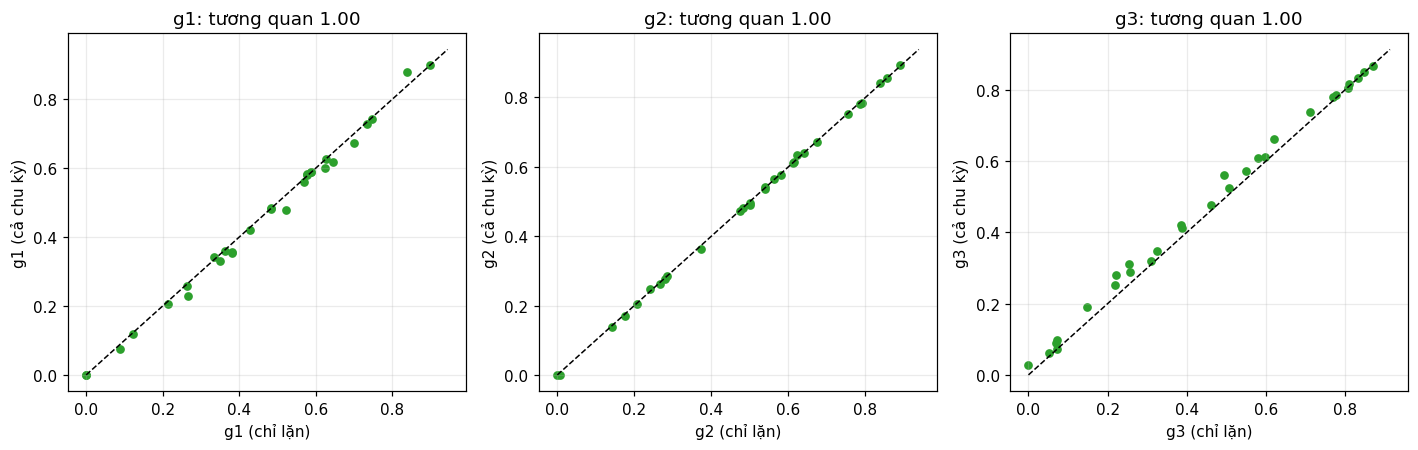

In [17]:
# (f) hai phương án có cho cùng g1-g3 trên các lần lặn có cả hai kết quả không?
both = F.join(G, lsuffix="_full", rsuffix="_dive", how="inner")
print(f"{len(both)} lần lặn có cả hai kết quả")
fig, ax = plt.subplots(1, 3, figsize=(13, 4.2))
for a, gc in zip(ax, ["g1", "g2", "g3"]):
    a.scatter(both[f"{gc}_dive"], both[f"{gc}_full"], s=22, color=COL["Type B venous"])
    lim = [0, max(both[f"{gc}_dive"].max(), both[f"{gc}_full"].max()) * 1.05 + 1e-6]
    a.plot(lim, lim, "k--", lw=1); a.set(xlabel=f"{gc} (chỉ lặn)", ylabel=f"{gc} (cả chu kỳ)", title=f"{gc}: tương quan {both[f'{gc}_dive'].corr(both[f'{gc}_full']):.2f}")
plt.tight_layout(); save_show("fig_full_vs_dive_g")

## 8b. Giới hạn của mô hình: sàn $S_v=0$ và lần lặn ngoại suy

Phương trình E2 không có sàn: $S_v$ mô hình có thể đi dưới 0, trong khi dữ liệu dừng ở 0 (hết oxy). Ô dưới đếm mức độ ảnh hưởng, và so sánh $g$ giữa lần lặn type B trong và ngoài giới hạn $T_d\le 11{,}7$ phút.

Bước này đếm các cú lặn mà mô hình đi xuống dưới 0 (vô lý về sinh lý) và so $g$ giữa cú lặn trong/ngoài giới hạn $T_d \le 11{,}7$ phút.

In [18]:
vd = ts[(ts["site"] == "venous") & ts["dive_id"].notna() & ~ts["excluded_dive"]].copy()
vd["group"] = vd["dive_id"].map(dv["group"])
print("Tỉ lệ mẫu trong lặn có S_v <= 0,02 (chạm sàn 0):")
display(vd.groupby("group")["Hb"].apply(lambda s_: (s_ <= 0.02).mean()).round(3).to_frame("ti_le"))

def model_min(did, option):
    d = ven.loc[did]; Td = d["Td"]; g = WIN[did]
    T = F if option == "full" else G
    th = T.loc[did, [c for c in ["S_init"] + G_COLS if c in T.columns]].to_dict()
    t0, t1 = (0.0, Td) if option == "dive" else (max(-PRE_WIN_S / 60, g["t_min"].min()), g["t_min"].max())
    return simulate_Sv(th, Td, R, TAU, t0, t1)[1].min()

chk = pd.concat([
    pd.DataFrame({"phuong_an": name, "group": T["group"].values, "extrapolated": T["extrapolated"].values,
                  "S_v_min": [model_min(i, opt) for i in T.index]})
    for name, T, opt in [("cả chu kỳ", F, "full"), ("chỉ lặn", G, "dive")]])
chk["duoi_0"] = chk["S_v_min"] < -0.02
print("S_v mô hình có đi xuống dưới 0 không? (đếm lần lặn có min < −0,02)")
display(chk.groupby(["phuong_an", "group"]).agg(so_lan_lan=("S_v_min", "size"), mo_hinh_duoi_0=("duoi_0", "sum"),
                                               S_v_min_trung_vi=("S_v_min", "median")).round(3))

print("Type B, chỉ lặn: g theo việc có ngoại suy (T_d > 11,7) hay không")
sB = G[G["group"] == "Type B venous"]
display(sB.groupby("extrapolated").agg(n=("Td", "size"), g1=("g1", "median"), g2=("g2", "median"), g3=("g3", "median"), rmse_trong_mau=("rmse_trong_mau", "median")).round(3))

Tỉ lệ mẫu trong lặn có S_v <= 0,02 (chạm sàn 0):


,ti_le
group,
Type A venous,0.000
Type B venous,0.011


S_v mô hình có đi xuống dưới 0 không? (đếm lần lặn có min < −0,02)


so_lan_lan  mo_hinh_duoi_0  S_v_min_trung_vi
phuong_an group                                                      
chỉ lặn   Type A venous          18               0             0.740
          Type B venous          61               5             0.319
cả chu kỳ Type A venous           3               0             0.357
          Type B venous          28               4             0.254

Type B, chỉ lặn: g theo việc có ngoại suy (T_d > 11,7) hay không


,n,g1,g2,g3,rmse_trong_mau
extrapolated,,,,,
False,45,0.429,0.483,0.324,0.045
True,16,0.246,0.447,0.576,0.069


## 8c. Chẩn đoán phần dư (phương án chỉ lặn)

Bước này kiểm tra xem phần dư có phải nhiễu độc lập hay có cấu trúc. Ba kiểm tra: (i) hệ số tự tương quan lag-1 của từng cú lặn; (ii) hàm tự tương quan trung bình theo độ trễ; (iii) phần dư trung bình theo $x=t/T_d$ để xem mô hình lệch có hệ thống ở đoạn nào.
Hệ quả của tự tương quan cao: số mẫu hiệu dụng $n_{eff}\approx n\,(1-\rho)/(1+\rho)$ nhỏ hơn nhiều so với $n$, nên R², AICc và khoảng tin cậy tính theo $n$ đều lạc quan.

Tự tương quan lag-1 của phần dư và số mẫu hiệu dụng (trung vị theo nhóm):


,so_lan_lan,n_trung_vi,rho1_trung_vi,n_eff_trung_vi,ti_le_rho1_lon_hon_0_3
group,,,,,
Type A venous,18,23.5,0.54,8.21,0.78
Type B venous,61,40.0,0.69,6.81,0.95


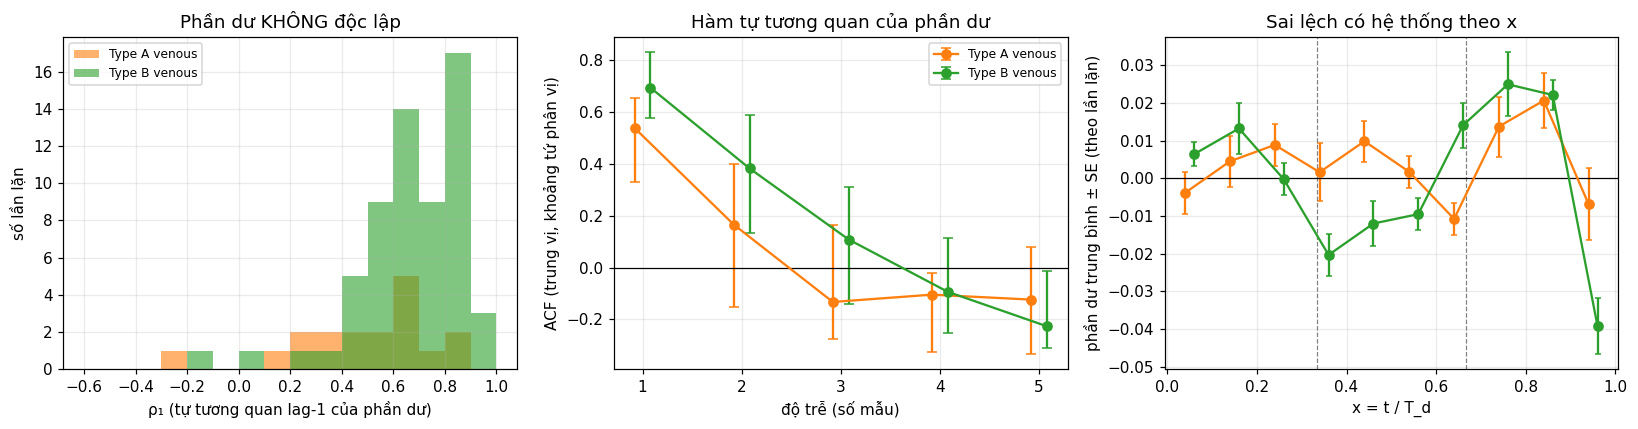

In [19]:
def resid_table(ids):
    out = []
    for did in ids:
        d, Td, g, T, tg_, Sv_, pred = fit_pack(did, "dive")
        gg = pd.DataFrame({"dive_id": did, "group": d["group"], "bird": d["bird"], "t_min": g["t_min"].values,
                           "x": g["t_min"].values / Td, "res": g["Hb"].values - pred}).sort_values("t_min")
        out.append(gg)
    return pd.concat(out, ignore_index=True)

def acf_lags(r, kmax=5):
    r = np.asarray(r, float) - np.mean(r); den = np.sum(r * r)
    return np.array([np.sum(r[:-k] * r[k:]) / den if (len(r) > k + 3 and den > 0) else np.nan for k in range(1, kmax + 1)])

RES_D = resid_table(G.index)
DIAG = []
for did, s in RES_D.groupby("dive_id"):
    ac = acf_lags(s["res"].values)
    rho = ac[0]
    n = len(s); neff = n * (1 - np.clip(rho, 0, 0.95)) / (1 + np.clip(rho, 0, 0.95)) if np.isfinite(rho) else np.nan
    DIAG.append({"dive_id": did, "group": s["group"].iloc[0], "bird": s["bird"].iloc[0], "n": n, "rho1": rho, "n_eff": neff,
                 **{f"acf{k+1}": ac[k] for k in range(5)}})
DIAG = pd.DataFrame(DIAG).set_index("dive_id")
print("Tự tương quan lag-1 của phần dư và số mẫu hiệu dụng (trung vị theo nhóm):")
display(DIAG.groupby("group").agg(so_lan_lan=("n", "size"), n_trung_vi=("n", "median"), rho1_trung_vi=("rho1", "median"),
                                  n_eff_trung_vi=("n_eff", "median"), ti_le_rho1_lon_hon_0_3=("rho1", lambda s: (s > 0.3).mean())).round(2))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
bins = np.linspace(-0.6, 1, 17)
for grp in GROUPS:
    ax[0].hist(DIAG.loc[DIAG["group"] == grp, "rho1"].dropna(), bins=bins, alpha=0.6, color=COL[grp], label=grp)
    m_ = DIAG[DIAG["group"] == grp][[f"acf{k}" for k in range(1, 6)]]
    ax[1].errorbar(np.arange(1, 6) + (0.08 if grp == GROUPS[1] else -0.08), m_.median(), yerr=[m_.median() - m_.quantile(.25), m_.quantile(.75) - m_.median()],
                   fmt="o-", color=COL[grp], capsize=3, label=grp)
ax[0].set(xlabel="ρ₁ (tự tương quan lag-1 của phần dư)", ylabel="số lần lặn", title="Phần dư KHÔNG độc lập"); ax[0].legend(fontsize=8)
ax[1].axhline(0, color="k", lw=0.8); ax[1].set(xlabel="độ trễ (số mẫu)", ylabel="ACF (trung vị, khoảng tứ phân vị)", title="Hàm tự tương quan của phần dư"); ax[1].legend(fontsize=8)
edges = np.linspace(0, 1, 11)
RES_D["xbin"] = np.clip(np.digitize(RES_D["x"], edges) - 1, 0, 9)
for grp in GROUPS:
    pm_ = RES_D[RES_D["group"] == grp].groupby(["dive_id", "xbin"])["res"].mean().unstack()
    mu_, se_ = pm_.mean(), pm_.std() / np.sqrt(pm_.count())
    ax[2].errorbar((edges[:-1] + edges[1:]) / 2 + (0.01 if grp == GROUPS[1] else -0.01), mu_.values, yerr=se_.values, fmt="o-", color=COL[grp], capsize=2, label=grp)
for v in (1/3, 2/3): ax[2].axvline(v, color="gray", ls="--", lw=0.8)
ax[2].axhline(0, color="k", lw=0.8); ax[2].set(xlabel="x = t / T_d", ylabel="phần dư trung bình ± SE (theo lần lặn)", title="Sai lệch có hệ thống theo x")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/fig_residual_diagnostics.png", dpi=140); plt.show()

## 8d. Mô hình $g$ hằng và mô hình 3 đoạn (AICc)

Bước này kiểm tra việc chia $g$ thành 3 đoạn có đáng giá so với một $g$ duy nhất cho cả cú lặn ($S_{init}, g$: 2 tham số) hay không. AICc phạt số tham số, nhưng giả định phần dư độc lập. Vì phần dư tự tương quan (mục 8c), bước này tính thêm **AICc hiệu chỉnh** dùng $n_{eff}$ thay cho $n$ trong số hạng sai số và số hạng phạt ($n_{eff}$ tính từ phần dư mô hình 3 đoạn, dùng chung cho cả hai mô hình): $\mathrm{AICc}_{eff}=n_{eff}\ln(SSE/n)+2k+\frac{2k(k+1)}{n_{eff}-k-1}$. Hai bản có thể cho kết luận ngược nhau; cách hiệu chỉnh dựa trên mô hình AR(1) thô và $n_{eff}$ nhỏ nên phạt rất nặng, vì vậy hai bản được xem như **hai cận** của mức bằng chứng, không có bản nào là đáp án cuối.

ΔAICc = AICc(3 đoạn) − AICc(g hằng); âm = 3 đoạn tốt hơn


,so_lan_lan,ti_le_3doan_thang,dAICc_trung_vi,ti_le_3doan_thang_hieu_chinh,dAICc_eff_trung_vi,rmse_g_hang,rmse_3_doan
group,,,,,,,
Type A venous,18,0.722,-15.051,0.278,9.558,0.042,0.025
Type B venous,61,0.984,-32.256,0.197,15.277,0.088,0.048


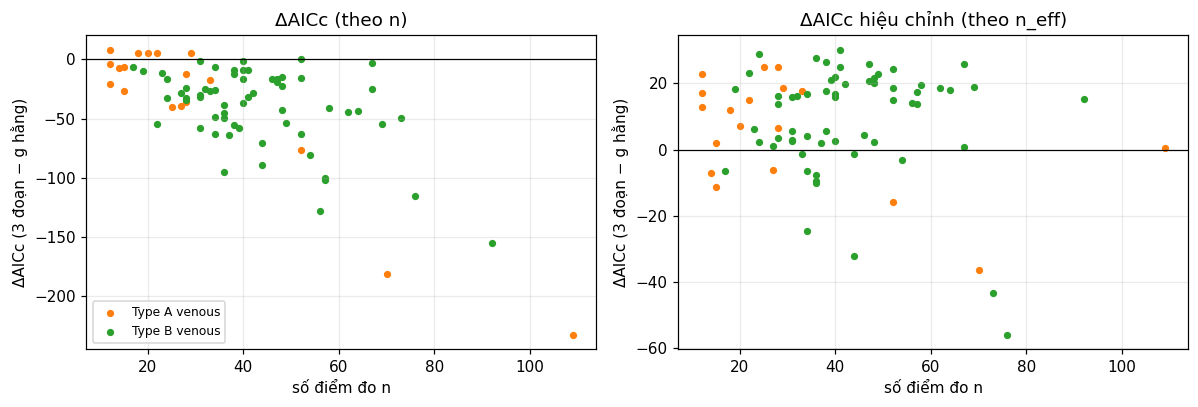

In [20]:
def fit_const_g(did):
    d = ven.loc[did]; g = WIN[did]; g = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])]
    B, b0, segs = _basis(d["Td"], g["t_min"].values, R, TAU, "dive")
    Bc = np.column_stack([B[:, 0], B[:, 1:].sum(axis=1)])                 # g1 = g2 = g3 = g
    y = g["Hb"].values
    sol = lsq_linear(Bc, y - b0, bounds=([0, 0], [1, G_MAX]))
    return float(np.sum((y - b0 - Bc @ sol.x) ** 2))

def aicc(sse, n, k):
    n = max(n, k + 2); return n * np.log(max(sse, 1e-12) / n) + 2 * k + 2 * k * (k + 1) / max(n - k - 1, 1)

def aicc_eff(sse, n, k, neff):
    neff = float(np.clip(neff, k + 2, n)); return neff * np.log(max(sse, 1e-12) / n) + 2 * k + 2 * k * (k + 1) / max(neff - k - 1, 1)

rows = []
for did in G.index:
    n = int(G.at[did, "n_rows"]); sse3 = (G.at[did, "rmse_trong_mau"] ** 2) * n; sse1 = fit_const_g(did); ne = DIAG.at[did, "n_eff"]
    ne = n if not np.isfinite(ne) else ne
    rows.append({"dive_id": did, "group": G.at[did, "group"], "bird": G.at[did, "bird"], "n": n, "n_eff": ne,
                 "dAICc": aicc(sse3, n, 4) - aicc(sse1, n, 2), "dAICc_eff": aicc_eff(sse3, n, 4, ne) - aicc_eff(sse1, n, 2, ne),
                 "rmse_const_g": np.sqrt(sse1 / n), "rmse_3seg": np.sqrt(sse3 / n)})
AICC_TAB = pd.DataFrame(rows).set_index("dive_id")
print("ΔAICc = AICc(3 đoạn) − AICc(g hằng); âm = 3 đoạn tốt hơn")
display(AICC_TAB.groupby("group").agg(so_lan_lan=("n", "size"),
        ti_le_3doan_thang=("dAICc", lambda s: (s < 0).mean()), dAICc_trung_vi=("dAICc", "median"),
        ti_le_3doan_thang_hieu_chinh=("dAICc_eff", lambda s: (s < 0).mean()), dAICc_eff_trung_vi=("dAICc_eff", "median"),
        rmse_g_hang=("rmse_const_g", "median"), rmse_3_doan=("rmse_3seg", "median")).round(3))
AICC_TAB.reset_index().to_csv(f"{RES_DIR}/aicc_const_vs_3seg.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for grp in GROUPS:
    s = AICC_TAB[AICC_TAB["group"] == grp]
    ax[0].scatter(s["n"], s["dAICc"], s=14, color=COL[grp], label=grp); ax[1].scatter(s["n"], s["dAICc_eff"], s=14, color=COL[grp])
for a_, t_ in zip(ax, ["ΔAICc (theo n)", "ΔAICc hiệu chỉnh (theo n_eff)"]):
    a_.axhline(0, color="k", lw=0.8); a_.set(xlabel="số điểm đo n", ylabel="ΔAICc (3 đoạn − g hằng)", title=t_)
ax[0].legend(fontsize=8); plt.tight_layout(); save_show("fig_aicc")

## 8e. Ngoài mẫu: leave-one-bird-out

Bước này đo khả năng **dự báo** của cấu trúc 3 đoạn trên chim chưa từng thấy:
1. Với mỗi chim bị bỏ, $g_1,g_2,g_3$ được ước lượng **chung theo nhóm** (Type A hoặc Type B) trên các chim còn lại; mỗi cú lặn huấn luyện vẫn có $S_{init}$ riêng.
2. $r$ lấy từ `R_NESTED` (không dùng chim bị bỏ).
3. Với cú lặn của chim bị bỏ, $S_{init}$ lấy từ **$S_v$ ngay trước lặn** (mẫu cuối trong 1 phút trước $t=0$, ngoài cú lặn). Cách này không dùng điểm đo nào trong cú lặn đang được đánh giá, tránh rò rỉ.
4. So với hai mốc: **đường chuẩn** "giữ nguyên $S_{init}$" (không động lực học) và **kết quả trong mẫu** của từng cú lặn.

Mô hình có khả năng dự báo nếu thắng đường chuẩn. Cột `rmse_lobo_r_toan_bo` dùng $r$ chọn trên toàn bộ dữ liệu, để đo mức rò rỉ do chọn $r$.

Cú lặn có S_v trước lặn (đủ điều kiện đánh giá ngoài mẫu): {'Type A venous': '18/18', 'Type B venous': '50/61'}
SO SÁNH TRONG MẪU và NGOÀI MẪU (trung vị theo cú lặn; skill = 1 − SSE_mô_hình/SSE_đường_chuẩn, dương = thắng đường chuẩn)


,so_lan_lan,so_chim,rmse_trong_mau,rmse_ngoai_mau,rmse_ngoai_mau_r_toan_bo,rmse_duong_chuan,skill_trung_vi,ti_le_thang_duong_chuan,ngoai_mau/trong_mau
group,,,,,,,,,
Type A venous,18,5,0.025,0.144,0.144,0.125,-0.861,0.389,5.854
Type B venous,50,8,0.048,0.262,0.265,0.277,0.384,0.640,5.505


Mức từng chim: số chim mà mô hình ngoài mẫu thắng đường chuẩn


,so_chim,so_chim_thang
group,,
Type A venous,5,2
Type B venous,8,6


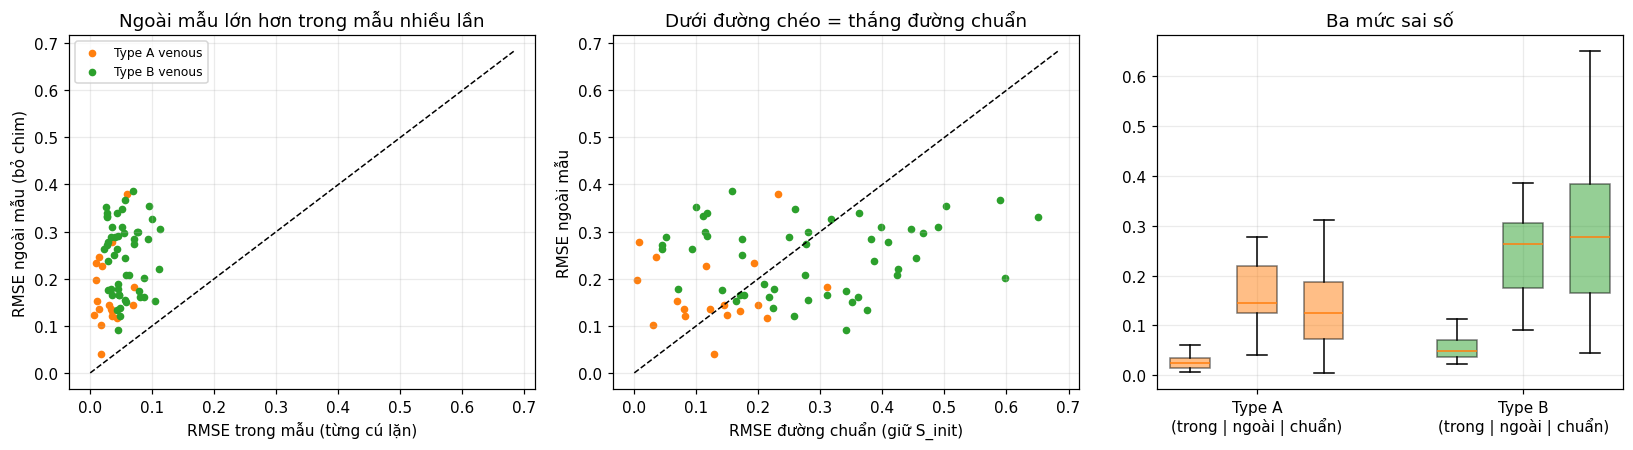

In [21]:
_SYS = {}
def dive_system(did, r):
    # Ma trận thiết kế (S_init, g1, g2, g3), phần cưỡng bức b0 và quan sát y của một cú lặn, tại hằng số trộn r
    key = (did, round(float(r), 8))
    if key not in _SYS:
        d = ven.loc[did]; g = WIN[did]; g = g[(g["t_min"] >= 0) & (g["t_min"] <= d["Td"])].sort_values("t_min")
        B, b0, _ = _basis(d["Td"], g["t_min"].values, r, TAU, "dive")
        _SYS[key] = (B, b0, g["Hb"].values)
    return _SYS[key]

def pre_dive_S(did):
    g = WIN[did]
    p = g[(g["t_min"] >= -PRE_SEARCH_MIN) & (g["t_min"] < 0) & g["dive_id"].isna() & ~g["unlisted_dive"]]
    return float(p.sort_values("t_min")["Hb"].iloc[-1]) if len(p) else np.nan

G["S_pre"] = [pre_dive_S(i) for i in G.index]
print("Cú lặn có S_v trước lặn (đủ điều kiện đánh giá ngoài mẫu):", G.groupby("group")["S_pre"].apply(lambda s: f"{s.notna().sum()}/{len(s)}").to_dict())

def pooled_g(ids, r):
    # g1,g2,g3 chung cho nhóm; mỗi cú lặn có S_init riêng (một bài toán bình phương tối thiểu có cận)
    blocks, ys = [], []
    for i, did in enumerate(ids):
        B, b0, y = dive_system(did, r)
        Z = np.zeros((len(y), len(ids) + 3)); Z[:, i] = B[:, 0]; Z[:, len(ids):] = B[:, 1:]
        blocks.append(Z); ys.append(y - b0)
    lo = np.zeros(len(ids) + 3); hi = np.r_[np.ones(len(ids)), np.full(3, G_MAX)]
    return lsq_linear(np.vstack(blocks), np.concatenate(ys), bounds=(lo, hi)).x[-3:]

def lobo_eval(r_of_bird):
    rows = []
    for grp in GROUPS:
        ids_grp = list(G.index[G["group"] == grp])
        for bird in sorted(G.loc[ids_grp, "bird"].unique()):
            test = [i for i in ids_grp if G.at[i, "bird"] == bird and np.isfinite(G.at[i, "S_pre"])]
            train = [i for i in ids_grp if G.at[i, "bird"] != bird]
            if not test or len(train) < 5: continue
            r_ = r_of_bird(bird); gh = pooled_g(train, r_)
            for did in test:
                B, b0, y = dive_system(did, r_); S0 = G.at[did, "S_pre"]
                p = B @ np.r_[S0, gh] + b0
                rows.append({"dive_id": did, "group": grp, "bird": bird, "n": len(y), "r_used": r_,
                             "sse_lobo": float(np.sum((y - p) ** 2)), "sse_naive": float(np.sum((y - S0) ** 2)),
                             "g1_pool": gh[0], "g2_pool": gh[1], "g3_pool": gh[2]})
    out = pd.DataFrame(rows).set_index("dive_id")
    out["rmse_lobo"] = np.sqrt(out["sse_lobo"] / out["n"]); out["rmse_naive"] = np.sqrt(out["sse_naive"] / out["n"])
    out["skill"] = 1 - out["sse_lobo"] / out["sse_naive"]
    return out

LOBO = lobo_eval(lambda b: R_NESTED[b])
LOBO_G = lobo_eval(lambda b: R)
LOBO["rmse_lobo_r_toan_bo"] = LOBO_G["rmse_lobo"]
LOBO["rmse_trong_mau"] = G.loc[LOBO.index, "rmse_trong_mau"]
LOBO.reset_index().to_csv(f"{RES_DIR}/validation_lobo_nested_r.csv", index=False)

def summarize_oos(L):
    s = L.groupby("group").agg(so_lan_lan=("n", "size"), so_chim=("bird", "nunique"),
                               rmse_trong_mau=("rmse_trong_mau", "median"), rmse_ngoai_mau=("rmse_lobo", "median"),
                               rmse_ngoai_mau_r_toan_bo=("rmse_lobo_r_toan_bo", "median"), rmse_duong_chuan=("rmse_naive", "median"),
                               skill_trung_vi=("skill", "median"))
    s["ti_le_thang_duong_chuan"] = L.groupby("group").apply(lambda d: (d["rmse_lobo"] < d["rmse_naive"]).mean(), include_groups=False)
    s["ngoai_mau/trong_mau"] = s["rmse_ngoai_mau"] / s["rmse_trong_mau"]
    return s.round(3)
print("SO SÁNH TRONG MẪU và NGOÀI MẪU (trung vị theo cú lặn; skill = 1 − SSE_mô_hình/SSE_đường_chuẩn, dương = thắng đường chuẩn)")
display(summarize_oos(LOBO))

# mức chim: mỗi chim một phiếu (chim có nhiều cú lặn không áp đảo)
BIRD_OOS = LOBO.groupby(["group", "bird"]).apply(lambda d: pd.Series({"n": len(d), "rmse_lobo": d["rmse_lobo"].median(), "rmse_naive": d["rmse_naive"].median()}), include_groups=False)
BIRD_OOS["thang"] = BIRD_OOS["rmse_lobo"] < BIRD_OOS["rmse_naive"]
print("Mức từng chim: số chim mà mô hình ngoài mẫu thắng đường chuẩn")
display(BIRD_OOS.groupby("group")["thang"].agg(so_chim="size", so_chim_thang="sum"))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for grp in GROUPS:
    s = LOBO[LOBO["group"] == grp]
    ax[0].scatter(s["rmse_trong_mau"], s["rmse_lobo"], s=16, color=COL[grp], label=grp)
    ax[1].scatter(s["rmse_naive"], s["rmse_lobo"], s=16, color=COL[grp])
lim = [0, max(LOBO["rmse_lobo"].max(), LOBO["rmse_naive"].max()) * 1.05]
ax[0].plot(lim, lim, "k--", lw=1); ax[0].set(xlabel="RMSE trong mẫu (từng cú lặn)", ylabel="RMSE ngoài mẫu (bỏ chim)", title="Ngoài mẫu lớn hơn trong mẫu nhiều lần"); ax[0].legend(fontsize=8)
ax[1].plot(lim, lim, "k--", lw=1); ax[1].set(xlabel="RMSE đường chuẩn (giữ S_init)", ylabel="RMSE ngoài mẫu", title="Dưới đường chéo = thắng đường chuẩn")
pos = 0
for grp in GROUPS:
    s = LOBO[LOBO["group"] == grp]
    for j, (col, lab) in enumerate([("rmse_trong_mau", "trong mẫu"), ("rmse_lobo", "ngoài mẫu"), ("rmse_naive", "chuẩn")]):
        ax[2].boxplot(s[col], positions=[pos + j], widths=0.6, showfliers=False, patch_artist=True, boxprops=dict(facecolor=COL[grp], alpha=0.5))
    pos += 4
ax[2].set_xticks([1, 5]); ax[2].set_xticklabels(["Type A\n(trong | ngoài | chuẩn)", "Type B\n(trong | ngoài | chuẩn)"]); ax[2].set_title("Ba mức sai số")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/fig_in_vs_out_of_sample.png", dpi=140); plt.show()

## 8f. Ước lượng co về trung vị nhóm

Bước này thử giảm overfit của mô hình từng cú lặn bằng cách **phạt độ lệch của $g$ so với trung vị nhóm** (ước lượng co, tương đương một phân phối tiên nghiệm Gauss quanh trung vị nhóm):

$$\min_{S_{init},g}\ \sum_i (S_{v,i}-\hat S_{v,i})^2\;+\;\lambda\,n\sum_{k=1}^{3}(g_k-\mu_k)^2,\qquad \mu_k=\text{trung vị } g_k \text{ của nhóm (các chim khác)}$$

$\lambda=0$ là cách khớp hiện tại; $\lambda\to\infty$ cố định $g_k=\mu_k$ và chỉ khớp $S_{init}$.

**Đánh giá.** Trung vị nhóm $\mu$ và mức co $\lambda$ chỉ được lấy từ các chim khác. Sai số được đo bằng **CV theo khối liền kề bên trong một cú lặn**: các điểm của cú lặn được chia thành 6 khối thời gian liền kề; lần lượt bỏ một khối, khớp trên 5 khối còn lại (quỹ đạo $S_v$ vẫn được mô phỏng liên tục), dự báo khối bỏ. CV theo khối (không phải xen kẽ) để tự tương quan không làm sai số quá nhỏ. Mức co $\lambda^*$ của mỗi chim bị bỏ được chọn từ các cú lặn của các chim còn lại (lồng nhau).

RMSE dự báo khối bị bỏ (CV theo khối, chim bị bỏ không tham gia μ và λ), trung vị theo cú lặn:


,so_lan_lan,lam_star_trung_vi,khong_co_lam0,co_lam_chon,co_het_muc_lam_inf,ti_le_co_thang_khong_co
group,,,,,,
Type A venous,18,0.002,0.048,0.050,0.147,0.056
Type B venous,61,0.003,0.094,0.095,0.257,0.311


Phân bố λ được chọn: {0.0: 39, 0.003: 40}


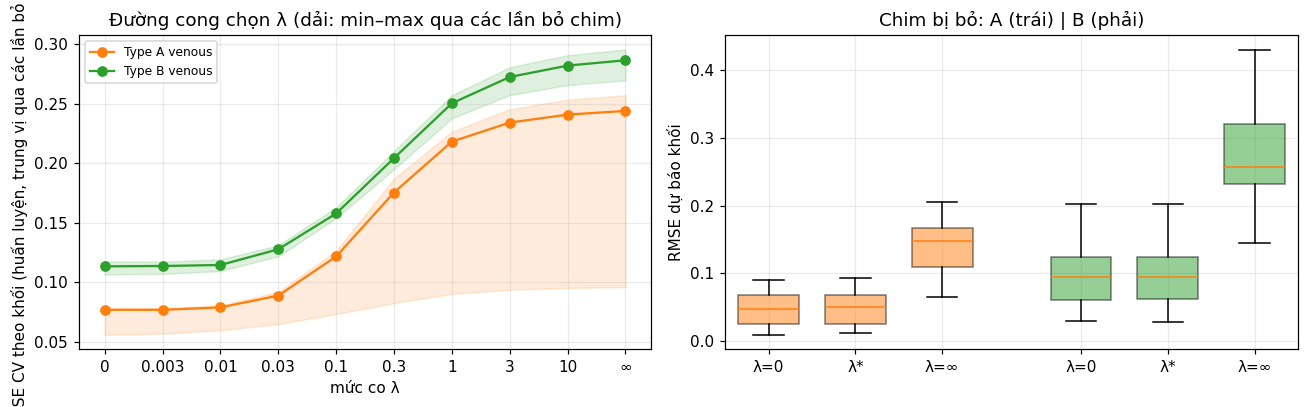

In [22]:
def fit_unshrunk(did, r):
    B, b0, y = dive_system(did, r)
    sol = lsq_linear(B, y - b0, bounds=(np.zeros(4), np.r_[1.0, np.full(3, G_MAX)]))
    return dict(zip(["S_init", "g1", "g2", "g3"], sol.x))

def shrink_fit(B, b0, y, mu, lam):
    n = len(y)
    if lam >= 1e5:                                      # g = mu cố định, chỉ khớp S_init
        sol = lsq_linear(B[:, :1], y - b0 - B[:, 1:] @ mu, bounds=([0.0], [1.0]))
        return np.r_[sol.x, mu]
    if lam <= 0:
        return lsq_linear(B, y - b0, bounds=(np.zeros(4), np.r_[1.0, np.full(3, G_MAX)])).x
    w = np.sqrt(lam * n)
    A = np.vstack([B, w * np.hstack([np.zeros((3, 1)), np.eye(3)])]); t = np.r_[y - b0, w * mu]
    return lsq_linear(A, t, bounds=(np.zeros(4), np.r_[1.0, np.full(3, G_MAX)])).x

def blocked_cv(did, r, mu, lam, K=N_BLOCKS):
    B, b0, y = dive_system(did, r); n = len(y); blk = np.minimum((np.arange(n) * K) // n, K - 1)
    sse, cnt = 0.0, 0
    for k in range(K):
        te = blk == k; tr = ~te
        if tr.sum() < 5 or te.sum() == 0: continue
        th = shrink_fit(B[tr], b0[tr], y[tr], mu, lam)
        e = y[te] - (B[te] @ th + b0[te]); sse += float(e @ e); cnt += int(te.sum())
    return sse, cnt

SHR_ROWS, LAM_ROWS = [], []
for bird in BIRDS_VEN:
    r_ = R_NESTED[bird]
    for grp in GROUPS:
        ids_grp = list(G.index[G["group"] == grp])
        train = [i for i in ids_grp if G.at[i, "bird"] != bird]; test = [i for i in ids_grp if G.at[i, "bird"] == bird]
        if not test or len(train) < 6: continue
        P = pd.DataFrame({i: fit_unshrunk(i, r_) for i in train}).T[["g1", "g2", "g3"]]
        birds_tr = G.loc[train, "bird"].values
        # (1) chọn λ chỉ từ chim huấn luyện; μ của mỗi cú lặn huấn luyện loại cả chim của nó
        sse_l = np.zeros(len(LAMBDA_GRID)); cnt_l = 0
        for i in train:
            mu_i = P[birds_tr != G.at[i, "bird"]].median().values
            for li, lam in enumerate(LAMBDA_GRID):
                s_, c_ = blocked_cv(i, r_, mu_i, lam); sse_l[li] += s_
            cnt_l += c_
        lam_star = LAMBDA_GRID[int(np.argmin(sse_l))]
        for li, lam in enumerate(LAMBDA_GRID):
            LAM_ROWS.append({"bird_out": bird, "group": grp, "lam": lam, "rmse_cv": np.sqrt(sse_l[li] / cnt_l)})
        # (2) đánh giá trên chim bị bỏ, μ từ mọi chim huấn luyện
        mu_e = P.median().values
        for did in test:
            row = {"dive_id": did, "group": grp, "bird": bird, "lam_star": lam_star}
            for name, lam in [("lam0", 0.0), ("lam_star", lam_star), ("lam_inf", 1e6)]:
                s_, c_ = blocked_cv(did, r_, mu_e, lam); row["rmse_" + name] = np.sqrt(s_ / c_)
            SHR_ROWS.append(row)
SHRINK = pd.DataFrame(SHR_ROWS).set_index("dive_id"); LAMC = pd.DataFrame(LAM_ROWS)
SHRINK.reset_index().to_csv(f"{RES_DIR}/shrinkage_blocked_cv.csv", index=False)

print("RMSE dự báo khối bị bỏ (CV theo khối, chim bị bỏ không tham gia μ và λ), trung vị theo cú lặn:")
tab = SHRINK.groupby("group").agg(so_lan_lan=("bird", "size"), lam_star_trung_vi=("lam_star", "median"),
                                  khong_co_lam0=("rmse_lam0", "median"), co_lam_chon=("rmse_lam_star", "median"), co_het_muc_lam_inf=("rmse_lam_inf", "median"))
tab["ti_le_co_thang_khong_co"] = SHRINK.groupby("group").apply(lambda d: (d["rmse_lam_star"] < d["rmse_lam0"]).mean(), include_groups=False)
display(tab.round(3))
print("Phân bố λ được chọn:", SHRINK["lam_star"].value_counts().sort_index().to_dict())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for grp in GROUPS:
    c = LAMC[LAMC["group"] == grp].groupby("lam")["rmse_cv"].agg(["median", "min", "max"])
    xs = np.arange(len(c)); ax[0].plot(xs, c["median"], "o-", color=COL[grp], label=grp); ax[0].fill_between(xs, c["min"], c["max"], color=COL[grp], alpha=0.15)
ax[0].set_xticks(np.arange(len(LAMBDA_GRID))); ax[0].set_xticklabels([("∞" if l >= 1e5 else f"{l:g}") for l in LAMBDA_GRID])
ax[0].set(xlabel="mức co λ", ylabel="RMSE CV theo khối (huấn luyện, trung vị qua các lần bỏ chim)", title="Đường cong chọn λ (dải: min–max qua các lần bỏ chim)"); ax[0].legend(fontsize=8)
for k, grp in enumerate(GROUPS):
    s = SHRINK[SHRINK["group"] == grp]
    bp = ax[1].boxplot([s["rmse_lam0"], s["rmse_lam_star"], s["rmse_lam_inf"]], positions=np.arange(3) + k * 3.6, widths=0.7, showfliers=False, patch_artist=True,
                       boxprops=dict(facecolor=COL[grp], alpha=0.5))
ax[1].set_xticks([0, 1, 2, 3.6, 4.6, 5.6]); ax[1].set_xticklabels(["λ=0", "λ*", "λ=∞"] * 2); ax[1].set(title="Chim bị bỏ: A (trái) | B (phải)", ylabel="RMSE dự báo khối")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/fig_shrinkage.png", dpi=140); plt.show()


## 9. Type A và type B có khác nhau không? (phương án chỉ lặn)

Các cú lặn của cùng một chim **không độc lập** (10 chim tĩnh mạch; nhiều chim có cả hai loại lặn), nên bootstrap và kiểm định theo cú lặn làm khoảng tin cậy quá hẹp và p quá nhỏ. Mục này làm lại ở mức cá thể:

1. **Bảng số cú lặn theo (chim, nhóm)** để biết mỗi chim đóng góp bao nhiêu.
2. **Khoảng tin cậy bootstrap hai tầng** cho trung vị nhóm: lấy mẫu chim có hoàn lại, rồi lấy mẫu các cú lặn trong từng chim.
3. **So A với B trong cùng một chim** (chỉ các chim có cả hai loại): kiểm định Wilcoxon cho cặp trung vị theo chim, và kiểm định hoán vị nhãn A/B **bên trong từng chim**.
4. Mann–Whitney theo cú lặn (bản gốc) giữ lại chỉ để **tham khảo**; giả định độc lập không thỏa.


Số cú lặn theo (chim, nhóm):


bird,EP04,EP05,EP07,EP17,EP19,EP20,EP36,EP37,EP40,EP48
group,,,,,,,,,,
Type A venous,3,5,7,1,2,0,0,0,0,0
Type B venous,0,6,0,8,15,2,5,6,2,17


,A_trung_vi,A_KTC95_theo_chim,B_trung_vi,B_KTC95_theo_chim,so_chim_co_ca_hai,B_hon_A_o_so_chim,p_Wilcoxon_theo_chim,p_hoan_vi_trong_chim,p_MannWhitney_theo_lan_lan(tham_khao)
g,,,,,,,,,
g1,0.0001,0.000–0.108,0.3801,0.175–0.624,3,3/3,0.25,0.0024,0.0000
g2,0.0537,0.000–0.175,0.4830,0.282–0.629,3,3/3,0.25,0.0011,0.0000
g3,0.1464,0.000–0.433,0.4224,0.195–0.712,3,2/3,0.50,0.2083,0.0032


Lưu ý 1: với n chim có cả hai loại lặn, p Wilcoxon hai phía nhỏ nhất là 2/2^n (n=3: 0,25; n=5: 0,0625), nên bài kiểm định này gần như không có sức mạnh khi n nhỏ.
Lưu ý 2: kiểm định hoán vị trong chim cho kết luận về các cú lặn của CHÍNH những chim này (coi các cú lặn trong một chim là hoán đổi được, bỏ qua khác biệt T_d và thứ tự lặn); không khái quát sang quần thể chim.


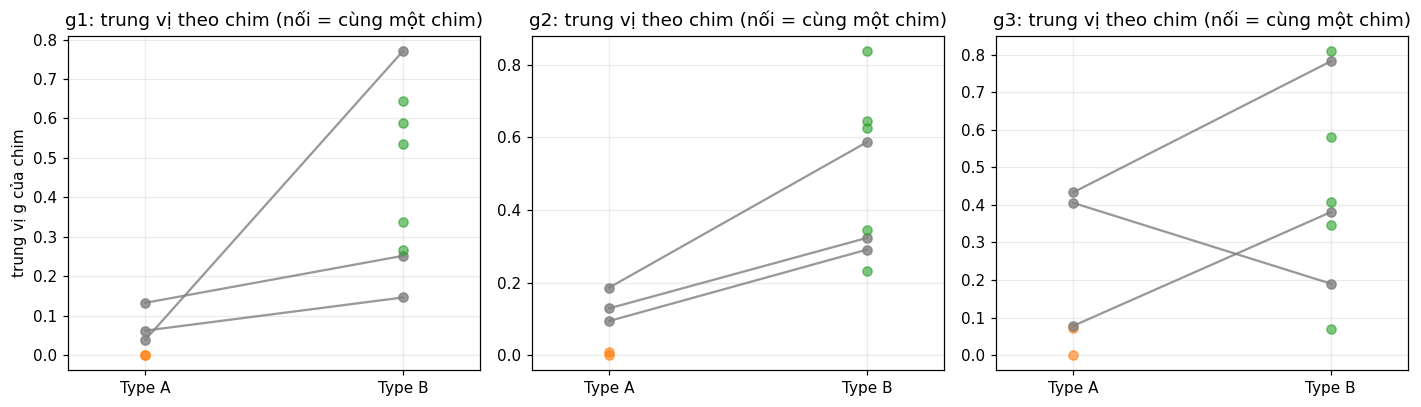


Tham khảo (bản gốc): Mann–Whitney theo cú lặn đã nằm ở cột cuối của bảng trên; KHÔNG dùng để kết luận vì các cú lặn cùng chim không độc lập.

Độ bền của hiệu trung vị (B − A) với việc loại cú lặn (dùng hiệu, không dùng tỉ số, vì trung vị g1 của Type A xấp xỉ 0):


,tập,n_A,n_B,g1_B−A,g2_B−A,g3_B−A
0,tất cả,18,61,0.38,0.43,0.28
1,bỏ cú lặn gắn cờ ít điểm,11,59,0.38,0.43,0.09
2,"bỏ cú lặn ngoại suy (T_d > 11,7)",18,45,0.43,0.43,0.18


In [23]:
GS = ["g1", "g2", "g3"]
BIRD_N = G.groupby(["bird", "group"]).size().unstack(fill_value=0)
print("Số cú lặn theo (chim, nhóm):"); display(BIRD_N.T)

def cluster_boot_median(df, col, B=N_BOOT_BIRD, seed=SEED):
    rng = np.random.default_rng(seed)
    byb = {b: s[col].values for b, s in df.groupby("bird")}; birds = np.array(list(byb))
    out = np.empty(B)
    for i in range(B):
        sb = rng.choice(birds, len(birds), replace=True)
        out[i] = np.median(np.concatenate([rng.choice(byb[b], len(byb[b]), replace=True) for b in sb]))
    return np.percentile(out, [2.5, 97.5])

def within_bird_perm(df, col, n_perm=N_PERM, seed=SEED):
    # thống kê: trung bình (qua các chim có cả hai loại) của [trung vị g của lần lặn B − trung vị g của lần lặn A];
    # hoán vị nhãn A/B bên trong từng chim
    rng = np.random.default_rng(seed)
    data = {b: (s[col].values, (s["group"] == "Type B venous").values) for b, s in df.groupby("bird") if s["group"].nunique() == 2}
    stat = lambda lab: np.mean([np.median(v[lab[b]]) - np.median(v[~lab[b]]) for b, (v, _) in data.items()])
    obs = stat({b: l for b, (v, l) in data.items()}); cnt = 0
    for _ in range(n_perm):
        if abs(stat({b: rng.permutation(l) for b, (v, l) in data.items()})) >= abs(obs) - 1e-12: cnt += 1
    return obs, (cnt + 1) / (n_perm + 1), len(data)

rows = []
for gc in GS:
    a_, b_ = G[G["group"] == GROUPS[0]], G[G["group"] == GROUPS[1]]
    ca, cb = cluster_boot_median(a_, gc), cluster_boot_median(b_, gc)
    pm = G.groupby(["bird", "group"])[gc].median().unstack().dropna()          # chim có cả A và B
    diff = (pm[GROUPS[1]] - pm[GROUPS[0]])
    p_w = wilcoxon(diff, alternative="two-sided").pvalue if len(diff) >= 3 and (diff != 0).any() else np.nan
    obs, p_perm, nb = within_bird_perm(G, gc)
    p_mw = mannwhitneyu(a_[gc], b_[gc], alternative="two-sided").pvalue
    rows.append({"g": gc, "A_trung_vi": a_[gc].median(), "A_KTC95_theo_chim": f"{ca[0]:.3f}–{ca[1]:.3f}", "B_trung_vi": b_[gc].median(),
                 "B_KTC95_theo_chim": f"{cb[0]:.3f}–{cb[1]:.3f}", "so_chim_co_ca_hai": nb, "B_hon_A_o_so_chim": f"{int((diff > 0).sum())}/{len(diff)}",
                 "p_Wilcoxon_theo_chim": p_w, "p_hoan_vi_trong_chim": p_perm, "p_MannWhitney_theo_lan_lan(tham_khao)": p_mw})
CMP = pd.DataFrame(rows).set_index("g"); display(CMP.round(4)); CMP.reset_index().to_csv(f"{RES_DIR}/compare_A_vs_B_bird_level.csv", index=False)
print("Lưu ý 1: với n chim có cả hai loại lặn, p Wilcoxon hai phía nhỏ nhất là 2/2^n (n=3: 0,25; n=5: 0,0625), nên bài kiểm định này gần như không có sức mạnh khi n nhỏ.")
print("Lưu ý 2: kiểm định hoán vị trong chim cho kết luận về các cú lặn của CHÍNH những chim này (coi các cú lặn trong một chim là hoán đổi được, bỏ qua khác biệt T_d và thứ tự lặn); không khái quát sang quần thể chim.")

BM = G.groupby(["bird", "group"])[GS].median()
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for a_, gc in zip(ax, GS):
    pm = BM[gc].unstack()
    for b, row in pm.iterrows():
        if row.notna().all(): a_.plot([0, 1], [row[GROUPS[0]], row[GROUPS[1]]], "o-", color="gray", alpha=0.8)
        else:
            k = 0 if np.isnan(row[GROUPS[1]]) else 1; a_.plot([k], [row[GROUPS[k]]], "o", color=COL[GROUPS[k]], alpha=0.6)
    a_.set_xticks([0, 1]); a_.set_xticklabels(["Type A", "Type B"]); a_.set_xlim(-0.3, 1.3); a_.set(title=f"{gc}: trung vị theo chim (nối = cùng một chim)")
ax[0].set_ylabel("trung vị g của chim")
plt.tight_layout(); plt.savefig(f"{IMG_DIR}/fig_bird_level_A_vs_B.png", dpi=140); plt.show()

print("\nTham khảo (bản gốc): Mann–Whitney theo cú lặn đã nằm ở cột cuối của bảng trên; KHÔNG dùng để kết luận vì các cú lặn cùng chim không độc lập.")

# độ bền: bỏ cú lặn gắn cờ ít điểm, bỏ cú lặn ngoại suy
chk = []
for name, mask in [("tất cả", np.ones(len(G), bool)), ("bỏ cú lặn gắn cờ ít điểm", ~G["warn_n"].values), ("bỏ cú lặn ngoại suy (T_d > 11,7)", ~G["extrapolated"].values)]:
    s = G[mask]; m_ = s.groupby("group")[GS].median()
    chk.append({"tập": name, "n_A": int((s["group"] == GROUPS[0]).sum()), "n_B": int((s["group"] == GROUPS[1]).sum()),
                **{f"{g}_B−A": m_.loc[GROUPS[1], g] - m_.loc[GROUPS[0], g] for g in GS}})
print("\nĐộ bền của hiệu trung vị (B − A) với việc loại cú lặn (dùng hiệu, không dùng tỉ số, vì trung vị g1 của Type A xấp xỉ 0):"); display(pd.DataFrame(chk).round(2))

## 9b. Độ nhạy theo $r$ và quy đổi $g$ sang hiệu số a-v

Bước này quét $r$ rộng hơn bản gốc và theo dõi cả **RMSE trong mẫu** lẫn $g$ trung vị, để xem kết luận có phụ thuộc vào $r$ hay không. Sau đó $g$ được đổi sang hiệu số a-v (mL O₂/dL) $=g\times 18\ \mathrm{g/dL}\times 1{,}34\ \mathrm{mL/g}$ để đối chiếu với Fig. 7 của bài báo (Type A $\approx$ 1–2,5 mL O₂/dL ở đầu cú lặn; Type B từ khoảng 1,5 tới 19).

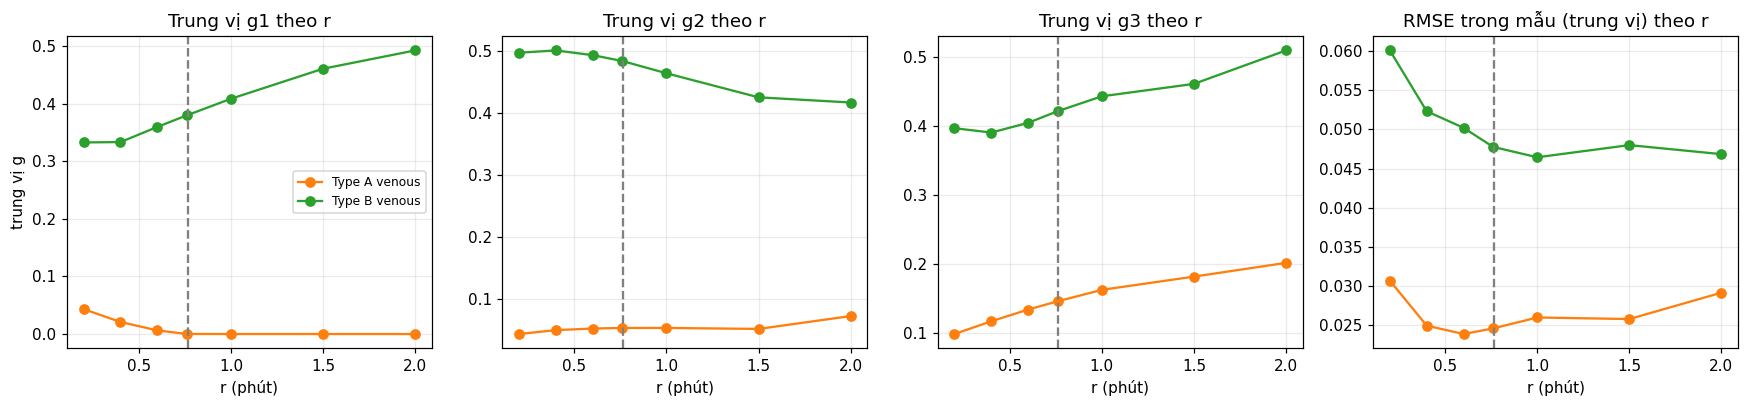

Hiệu trung vị g_B − g_A theo r (dương: Type B có g lớn hơn):


,g1,g2,g3
r,,,
0.20,0.289,0.453,0.299
0.40,0.312,0.450,0.274
0.60,0.353,0.440,0.271
0.76,0.380,0.430,0.276
1.00,0.409,0.410,0.281
1.50,0.461,0.373,0.280
2.00,0.492,0.344,0.308


Quy đổi: a-v = g × 24.12 mL O2/dL


,nhóm,g,g_trung_vi,a-v (mL O2/dL),KTC95 theo chim (mL O2/dL)
0,Type A venous,g1,0.000,0.001,0.0–2.6
1,Type B venous,g1,0.380,9.169,4.2–15.0
2,Type A venous,g2,0.054,1.294,0.0–4.2
3,Type B venous,g2,0.483,11.650,6.8–15.2
4,Type A venous,g3,0.146,3.530,0.0–10.4
5,Type B venous,g3,0.422,10.189,4.7–17.2


In [24]:
R_SENS = sorted(set([0.2, 0.4, 0.6, round(R, 2), 1.0, 1.5, 2.0]))
rows = []
for rr in R_SENS:
    for did in G.index:
        B, b0, y = dive_system(did, rr)
        sol = lsq_linear(B, y - b0, bounds=(np.zeros(4), np.r_[1.0, np.full(3, G_MAX)]))
        rows.append({"r": rr, "group": G.at[did, "group"], "rmse_trong_mau": np.sqrt(np.mean((y - b0 - B @ sol.x) ** 2)),
                     "g1": sol.x[1], "g2": sol.x[2], "g3": sol.x[3]})
SENS = pd.DataFrame(rows)
med = SENS.groupby(["r", "group"]).median().reset_index()
fig, ax = plt.subplots(1, 4, figsize=(16, 3.8))
for a_, gc in zip(ax[:3], GS):
    for grp in GROUPS:
        s = med[med["group"] == grp]; a_.plot(s["r"], s[gc], "o-", color=COL[grp], label=grp)
    a_.axvline(R, color="gray", ls="--"); a_.set(title=f"Trung vị {gc} theo r", xlabel="r (phút)")
for grp in GROUPS:
    s = med[med["group"] == grp]; ax[3].plot(s["r"], s["rmse_trong_mau"], "o-", color=COL[grp])
ax[3].axvline(R, color="gray", ls="--"); ax[3].set(title="RMSE trong mẫu (trung vị) theo r", xlabel="r (phút)")
ax[0].set_ylabel("trung vị g"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(f"{IMG_DIR}/fig_sensitivity_r.png", dpi=140); plt.show()
print("Hiệu trung vị g_B − g_A theo r (dương: Type B có g lớn hơn):")
rat = med.pivot(index="r", columns="group", values=["g1", "g2", "g3"])
display(pd.DataFrame({gc: rat[gc][GROUPS[1]] - rat[gc][GROUPS[0]] for gc in GS}).round(3))

rows = []
for gc in GS:
    for grp in GROUPS:
        s = G[G["group"] == grp]; ci = cluster_boot_median(s, gc)
        rows.append({"nhóm": grp, "g": gc, "g_trung_vi": s[gc].median(), "a-v (mL O2/dL)": s[gc].median() * AV_FACTOR,
                     "KTC95 theo chim (mL O2/dL)": f"{ci[0]*AV_FACTOR:.1f}–{ci[1]*AV_FACTOR:.1f}"})
AV = pd.DataFrame(rows); print(f"Quy đổi: a-v = g × {AV_FACTOR:.2f} mL O2/dL"); display(AV.round(3)); AV.to_csv(f"{RES_DIR}/g_in_mL_O2_per_dL.csv", index=False)

## 9c. Nghịch đảo trực tiếp $g(t)$

Bước này ước lượng $g(t)$ **không giả định hằng từng đoạn**, để kiểm tra giả định 3 đoạn. Từ công thức (9): $g_j=S_a(t_j)-\dfrac{S_{v,j+1}-a\,S_{v,j}}{1-a}$ với $a=e^{-\Delta t/r}$. Công thức khuếch đại nhiễu hệ số $1/(1-a)$ (≈16 lần với $r\approx0{,}76$), nên $S_v$ đo được nội suy lên lưới 0,05 phút và làm trơn Savitzky–Golay (cửa sổ 1 phút, bậc 2) trước khi nghịch đảo. Sau đó $g$ nghịch đảo được lấy trung bình trong từng phần ba của cú lặn để so với $g_1,g_2,g_3$ đã khớp (tương quan Spearman trên mọi cú lặn). Hai ước lượng cùng xuất phát từ một chuỗi $S_v$ nên tương quan cao chỉ cho thấy **mức trung bình trong từng đoạn nhất quán**; biến thiên bên trong một đoạn (xem hình) mới là chỗ giả định hằng từng đoạn bị thử thách.

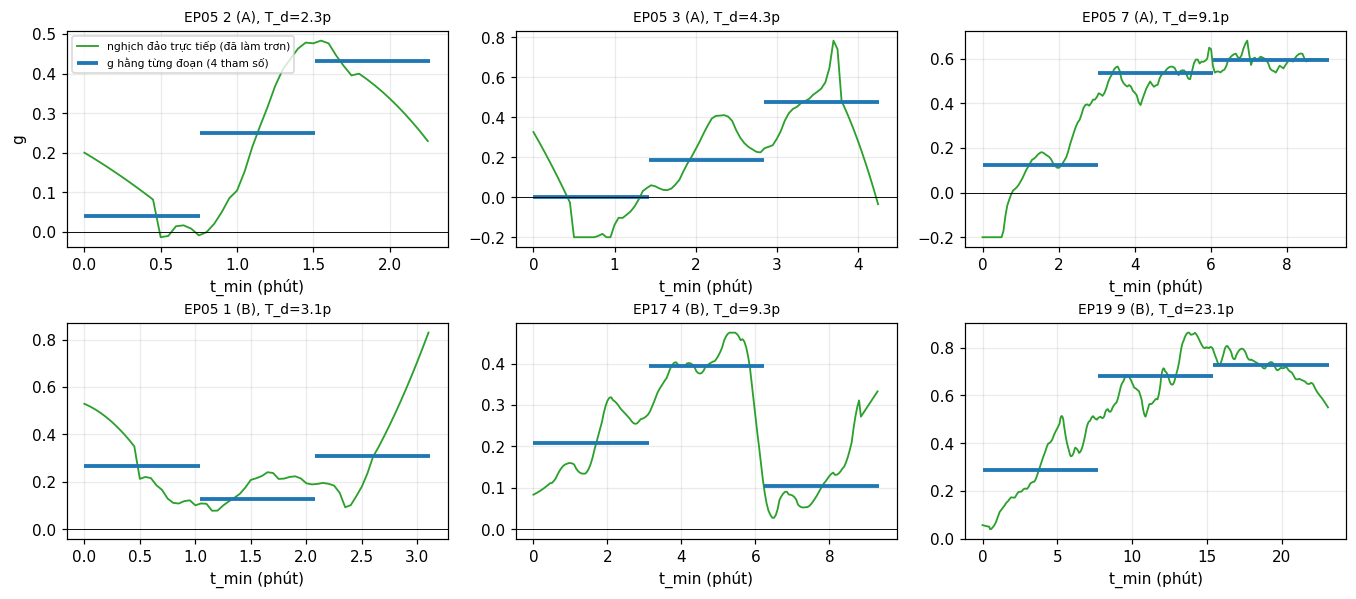

Tương quan Spearman giữa g khớp (hằng từng đoạn) và trung bình g nghịch đảo trong cùng đoạn:


n  spearman  lech_trung_binh
group         g                                  
Type A venous g1  18.0      0.83            -0.00
              g2  18.0      0.99             0.01
              g3  18.0      0.95            -0.01
Type B venous g1  61.0      0.99            -0.01
              g2  61.0      0.99            -0.00
              g3  61.0      1.00             0.02

In [25]:
def g_inverse(did, r=None, win_min=1.0):
    r = R if r is None else r
    Td = ven.loc[did, "Td"]; g = WIN[did]; g = g[(g["t_min"] >= 0) & (g["t_min"] <= Td)].sort_values("t_min")
    n = int(np.ceil(Td / DT_MIN)) + 1; tg = DT_MIN * np.arange(n)
    Sv = np.interp(tg, g["t_min"].values, g["Hb"].values)
    w = int(round(win_min / DT_MIN)) // 2 * 2 + 1; w = max(5, min(w, (len(tg) // 2) * 2 - 1))
    Sv_s = savgol_filter(Sv, w, 2)
    a = np.exp(-DT_MIN / r)
    ginv = Sa_template(tg[:-1], Td, TAU) - (Sv_s[1:] - a * Sv_s[:-1]) / (1 - a)
    return tg[:-1], np.clip(ginv, -0.2, 1.0)

fig = plt.figure(figsize=(15, 6)); outer = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.18)
for k, did in enumerate(pick_spread(G, GROUPS[0], 3) + pick_spread(G, GROUPS[1], 3)):
    a = fig.add_subplot(outer[k // 3, k % 3]); Td = ven.loc[did, "Td"]; tgi, gi = g_inverse(did)
    a.plot(tgi, gi, color="tab:green", lw=1.2, label="nghịch đảo trực tiếp (đã làm trơn)")
    edges_ = [0, Td/3, 2*Td/3, Td]
    for j, gc in enumerate(GS): a.hlines(G.at[did, gc], edges_[j], edges_[j + 1], color="tab:blue", lw=2.5, label="g hằng từng đoạn (4 tham số)" if j == 0 else None)
    a.axhline(0, color="k", lw=0.6); a.set_title(f"{did} ({G.at[did,'group'].split()[1]}), T_d={Td:.1f}p", fontsize=9); a.set_xlabel("t_min (phút)")
fig.axes[0].legend(fontsize=7); fig.axes[0].set_ylabel("g")
fig.savefig(f"{IMG_DIR}/fig_g_inverse.png", dpi=140, bbox_inches="tight"); plt.show()

rows = []
for did in G.index:
    Td = ven.loc[did, "Td"]; tgi, gi = g_inverse(did); e = [0, Td/3, 2*Td/3, Td + 1e-9]
    for j, gc in enumerate(GS):
        m = (tgi >= e[j]) & (tgi < e[j + 1]); rows.append({"dive_id": did, "group": G.at[did, "group"], "g": gc, "g_fit": G.at[did, gc], "g_inv": gi[m].mean()})
INV = pd.DataFrame(rows)
print("Tương quan Spearman giữa g khớp (hằng từng đoạn) và trung bình g nghịch đảo trong cùng đoạn:")
display(INV.groupby(["group", "g"]).apply(lambda d: pd.Series({"n": len(d), "spearman": d["g_fit"].corr(d["g_inv"], method="spearman"),
                                                                 "lech_trung_binh": (d["g_inv"] - d["g_fit"]).mean()}), include_groups=False).round(2))

## 10. Xuất kết quả

Bước này ghi các bảng khớp, cửa sổ và tham số ước lượng và các kết quả kiểm định vào `../results` (hình ảnh nằm trong `../results/images`).

In [26]:
F.reset_index().to_csv(f"{RES_DIR}/venous_fit_full_cycle.csv", index=False)
G.reset_index().to_csv(f"{RES_DIR}/venous_fit_dive_only.csv", index=False)
W.reset_index().to_csv(f"{RES_DIR}/venous_windows.csv", index=False)

params = {
    "constants": {"P50": P50, "n_hill": N_HILL, "S_REST": S_REST, "S_DIVE0": S_DIVE0, "K_EXP": K_EXP,
                  "dSa_formula": "clip(-0.141 + 0.183 ln Td, 0, 0.6)", "TD_MAX_ART": TD_MAX_ART, "DT_MIN": DT_MIN},
    "estimated": {"tau_a_min": TAU, "tau_a_ci95": [float(tau_ci[0]), float(tau_ci[1])], "r_min": R},
    "counts": {"n_full_cycle": int(len(F)), "n_dive_only": int(len(G)), "n_clean_windows": int(W["clean"].sum()),
               "n_venous_dives": int(len(W))},
}
with open(f"{RES_DIR}/model_params.json", "w", encoding="utf-8") as fh:
    json.dump(params, fh, ensure_ascii=False, indent=2)
print("Đã xuất: venous_fit_full_cycle.csv | venous_fit_dive_only.csv | venous_windows.csv | model_params.json ->", RES_DIR)

# ---- kết quả mới (mục 6b, 8c–8f, 9, 9b) vào ../results ----
params["estimated"]["r_nested_by_held_out_bird"] = {k: float(v) for k, v in R_NESTED.items()}
params["constants"]["MIN_ROWS_DIVE"] = MIN_ROWS_DIVE
params["counts"]["n_dive_only_warn_n"] = int(G["warn_n"].sum())
with open(f"{RES_DIR}/model_params.json", "w", encoding="utf-8") as fh:
    json.dump(params, fh, ensure_ascii=False, indent=2)
G.reset_index().to_csv(f"{RES_DIR}/venous_fit_dive_only_with_flags.csv", index=False)
DIAG.reset_index().to_csv(f"{RES_DIR}/residual_diagnostics.csv", index=False)
LAMC.to_csv(f"{RES_DIR}/shrinkage_lambda_curve.csv", index=False)
BM.reset_index().to_csv(f"{RES_DIR}/bird_level_median_g.csv", index=False)
SENS.to_csv(f"{RES_DIR}/sensitivity_r.csv", index=False)
print("Đã xuất thêm vào", RES_DIR)


Đã xuất: venous_fit_full_cycle.csv | venous_fit_dive_only.csv | venous_windows.csv | model_params.json -> ../results
Đã xuất thêm vào ../results
